In [1]:
import numpy as np
from matplotlib import pyplot as plt
%matplotlib inline

from astropy.io import fits
from glob import glob
#from scipy.optimize import curve_fit

import photutils
from photutils import aperture # CircularAperture, CircularAnnulus # aperture_photometry, 
# need to work out *what* I need from photutils, some things seem to have been renamed

# Set-up

## Importing 

### Science Camera Images

#### Data for Section 10.2 "First Observation"
Files saved starting with: "obs1_*.fits"
- All observations taken with t_exposure = 30 secs
- default filter = R, otherwise the filter used is stated

In [24]:
filepath = "Data/" # directory data files are in, can be altered 
filepaths_obs1 = glob(filepath+"obs1_*.fits")
filepaths_obs1

['Data\\obs1_star1_app1_30s.fits',
 'Data\\obs1_star1_app2_30s.fits',
 'Data\\obs1_star1_app3_30s.fits',
 'Data\\obs1_star1_app4_30s_B.fits',
 'Data\\obs1_star1_app4_30s_C.fits',
 'Data\\obs1_star1_app4_30s_G.fits',
 'Data\\obs1_star1_app4_30s_R.fits']

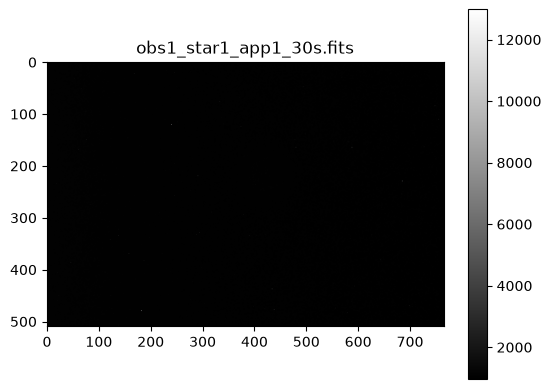

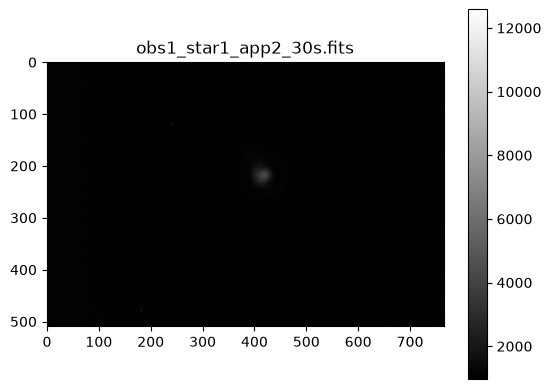

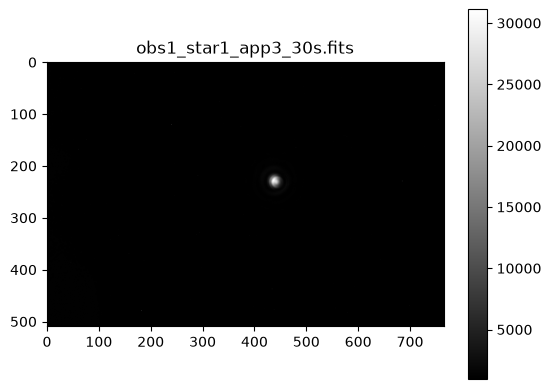

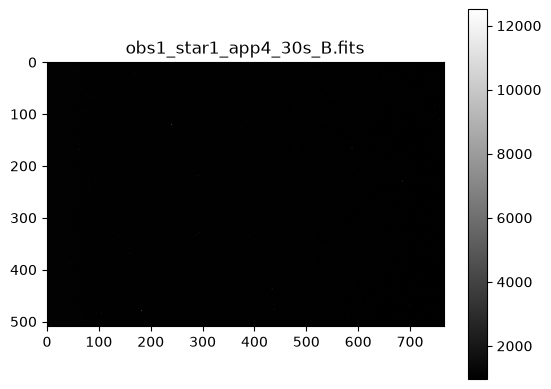

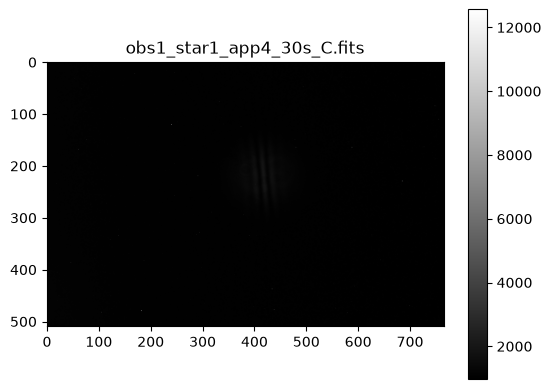

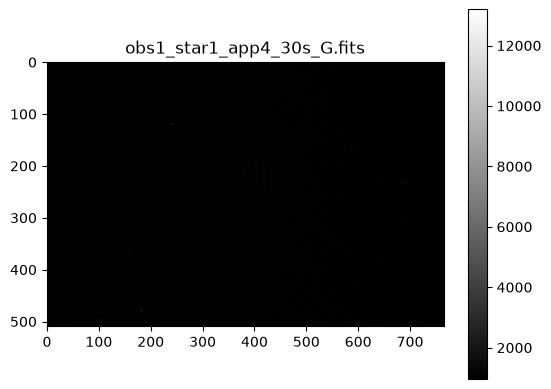

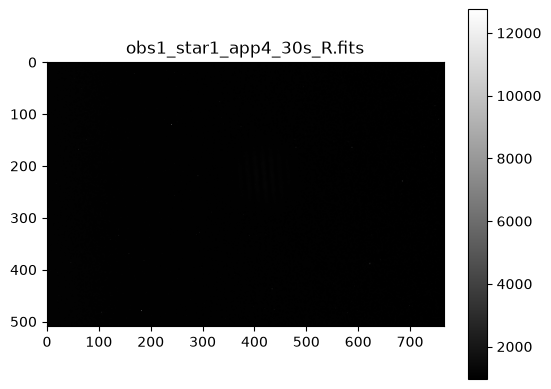

In [69]:
# open image files, check, & save
obs1_array, obs1_headers_list = [], []
for img in filepaths_obs1:
    file = fits.open(img)
    obs1_headers_list.append(file[0].header)
    file = file[0].data
    file = file.astype('int32')
    plt.figure()
    plt.imshow(file, cmap='gray')
    plt.colorbar()
    plt.title(img[5:])
    #plt.close()
    obs1_array.append(file)

In [74]:
for header in obs1_headers_list:
    print(header, '\n~~~~~~~~~~~~~~~~~~~~~~~~~~~~\n')

SIMPLE  =                    T / Fits standard                                  BITPIX  =                   16 / number of bits per data pixel                  NAXIS   =                    2 / number of data axes                            NAXIS1  =                  765 / length of data axis 1                          NAXIS2  =                  510 / length of data axis 2                          EXTEND  =                    T / FITS dataset may contain extensions            COMMENT   FITS (Flexible Image Transport System) format is defined in 'AstronomyCOMMENT   and Astrophysics', volume 376, page 359; bibcode: 2001A&A...376..359H BZERO   =                32768 / offset data range to that of unsigned short    BSCALE  =                    1 / default scaling factor                         INSTRUME= 'SBIG ST402'         / Image CCD                                      EXPTIME =                  30. / exposure time (seconds)                        DATE    = '14:15:14 2026-11-03'         

In [94]:
obs1_headers_list[0]

SIMPLE  =                    T / Fits standard                                  
BITPIX  =                   16 / number of bits per data pixel                  
NAXIS   =                    2 / number of data axes                            
NAXIS1  =                  765 / length of data axis 1                          
NAXIS2  =                  510 / length of data axis 2                          
EXTEND  =                    T / FITS dataset may contain extensions            
COMMENT   FITS (Flexible Image Transport System) format is defined in 'Astronomy
COMMENT   and Astrophysics', volume 376, page 359; bibcode: 2001A&A...376..359H 
BZERO   =                32768 / offset data range to that of unsigned short    
BSCALE  =                    1 / default scaling factor                         
INSTRUME= 'SBIG ST402'         / Image CCD                                      
EXPTIME =                  30. / exposure time (seconds)                        
DATE    = '14:15:14 2026-11-

### [Bias / Flats / Darks] for Reducing the Science Camera Images

<u>Need to take:<u>
- bias images
    - taken with closed shutter & ~ 0 second exposure time
    - should take *multiple* bias images 
- flats [images]
    - to take a flat field image, must uniformly illuminate the CCD (& not over-exposure) => could uniformly illuminate white screen/sheet of paper?
    - each filter should have its own set of flats
    - exposure time => 
- dark images
    - taken with closed shutter. Exposure time can vary => could match to observation exposure time. 



Will take:
- [multiple] dark images w/30 second exposure
    - (our dark images will double as our bias images) 
- [ multiple] flat field images w/30 second exposure

In [4]:
filepaths_darks = glob(filepath+"dark_*.fits")
filepaths_darks

['Data\\dark_30s_1.fits',
 'Data\\dark_30s_10.fits',
 'Data\\dark_30s_2.fits',
 'Data\\dark_30s_3.fits',
 'Data\\dark_30s_4.fits',
 'Data\\dark_30s_5.fits',
 'Data\\dark_30s_6.fits',
 'Data\\dark_30s_7.fits',
 'Data\\dark_30s_8.fits',
 'Data\\dark_30s_9.fits']

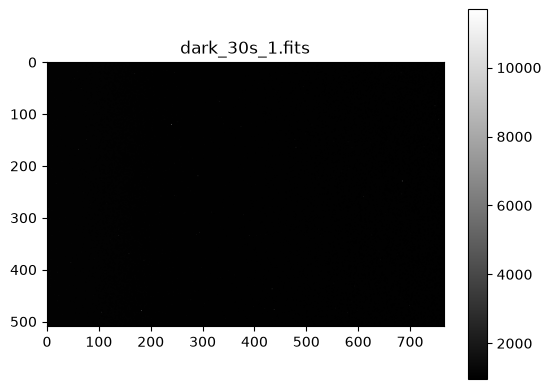

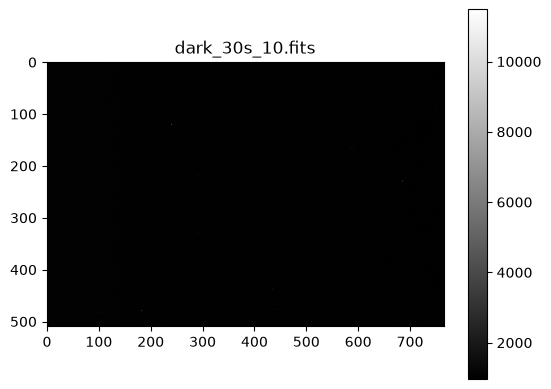

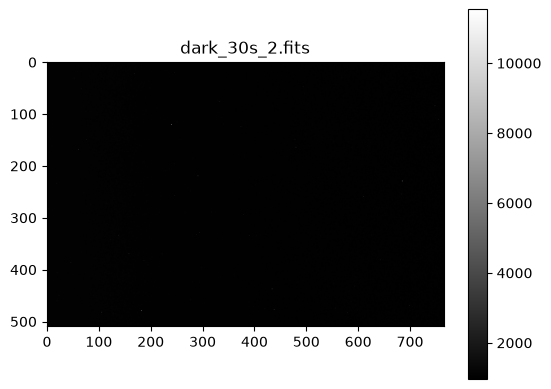

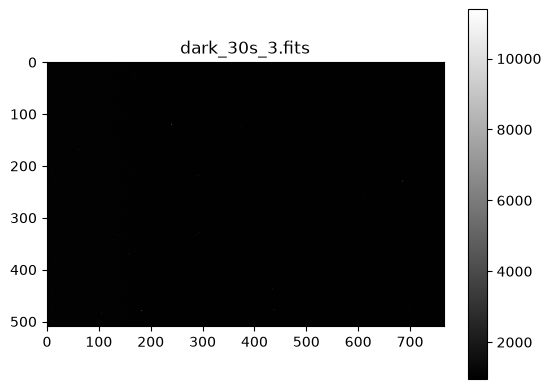

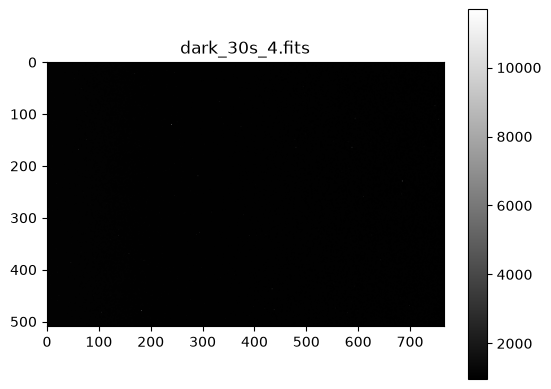

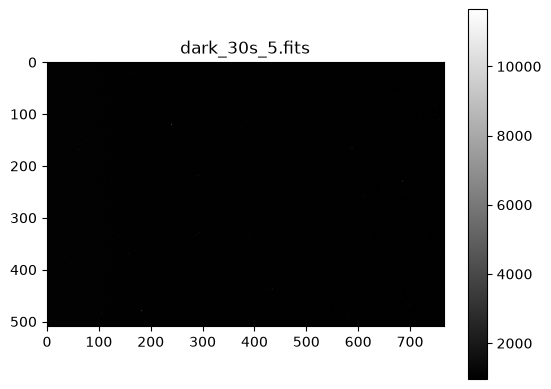

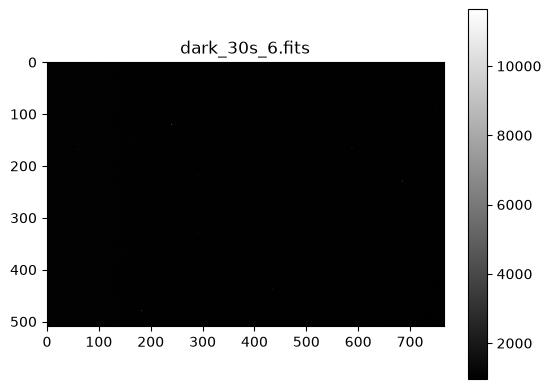

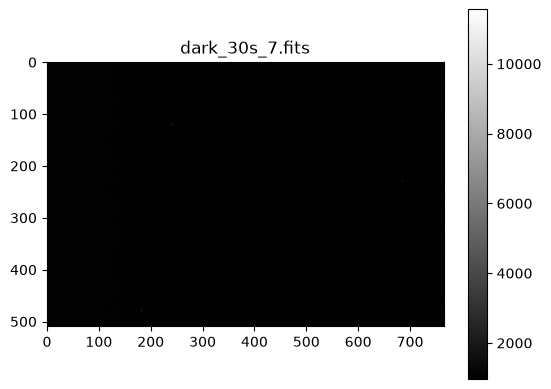

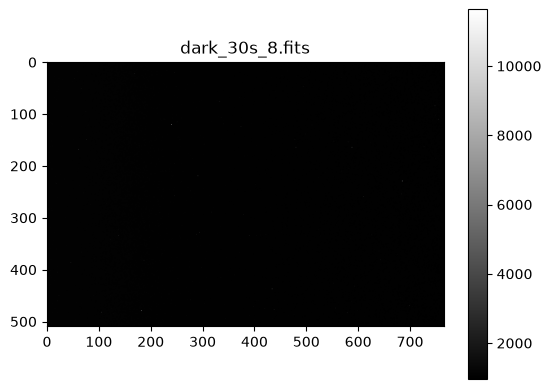

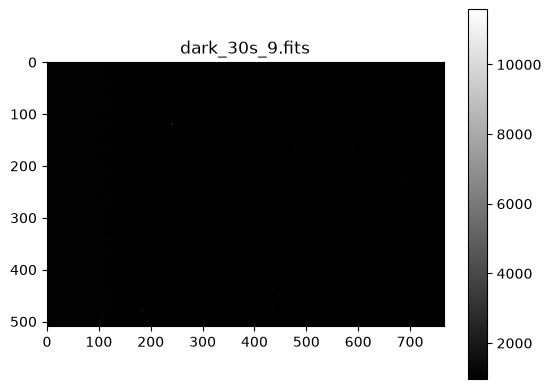

In [5]:
# open image files, check, & save
darks_array = []
for img in filepaths_darks:
    file = fits.open(img)
    file = file[0].data
    file = file.astype('int32')
    plt.figure()
    plt.imshow(file, cmap='gray')
    plt.colorbar()
    plt.title(img[5:])
    darks_array.append(file)

In [14]:
filepaths_flats = glob(filepath+"flat_*.fits") # the *old* r_filters = unlabelled [retook as light outside has changed]
filepaths_flats

['Data\\flat_30s_1.fits',
 'Data\\flat_30s_10.fits',
 'Data\\flat_30s_10_B.fits',
 'Data\\flat_30s_10_C.fits',
 'Data\\flat_30s_10_G.fits',
 'Data\\flat_30s_10_R.fits',
 'Data\\flat_30s_1_B.fits',
 'Data\\flat_30s_1_C.fits',
 'Data\\flat_30s_1_G.fits',
 'Data\\flat_30s_1_R.fits',
 'Data\\flat_30s_2.fits',
 'Data\\flat_30s_2_B.fits',
 'Data\\flat_30s_2_C.fits',
 'Data\\flat_30s_2_G.fits',
 'Data\\flat_30s_2_R.fits',
 'Data\\flat_30s_3.fits',
 'Data\\flat_30s_3_B.fits',
 'Data\\flat_30s_3_C.fits',
 'Data\\flat_30s_3_G.fits',
 'Data\\flat_30s_3_R.fits',
 'Data\\flat_30s_4.fits',
 'Data\\flat_30s_4_B.fits',
 'Data\\flat_30s_4_C.fits',
 'Data\\flat_30s_4_G.fits',
 'Data\\flat_30s_4_R.fits',
 'Data\\flat_30s_5.fits',
 'Data\\flat_30s_5_B.fits',
 'Data\\flat_30s_5_C.fits',
 'Data\\flat_30s_5_G.fits',
 'Data\\flat_30s_5_R.fits',
 'Data\\flat_30s_6.fits',
 'Data\\flat_30s_6_B.fits',
 'Data\\flat_30s_6_C.fits',
 'Data\\flat_30s_6_G.fits',
 'Data\\flat_30s_6_R.fits',
 'Data\\flat_30s_7.fits',
 'D

C:\Users\cathe\AppData\Local\Temp\ipykernel_17424\1889385438.py:7: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  plt.figure()


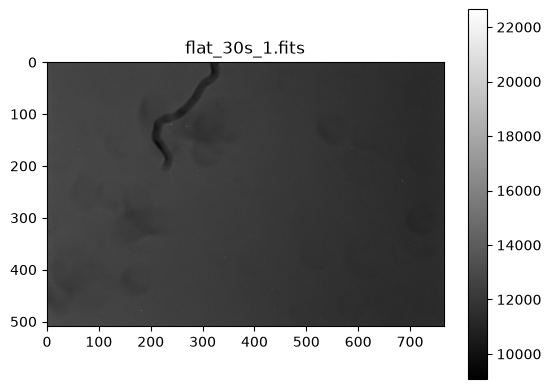

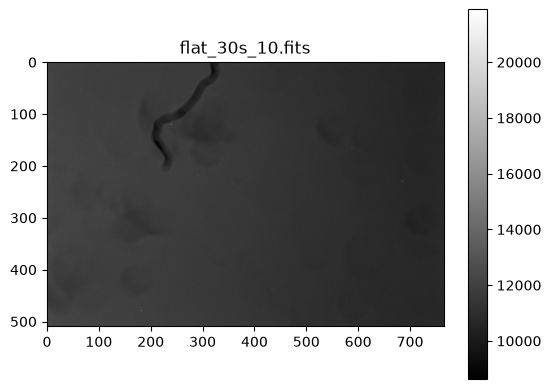

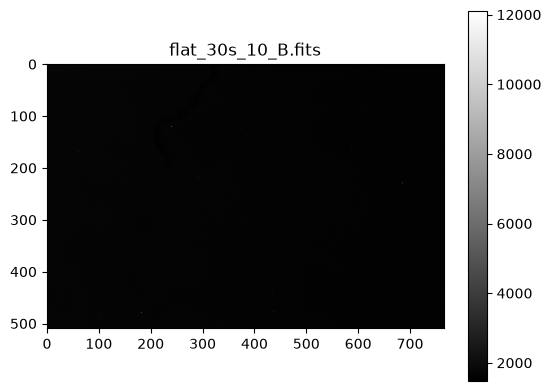

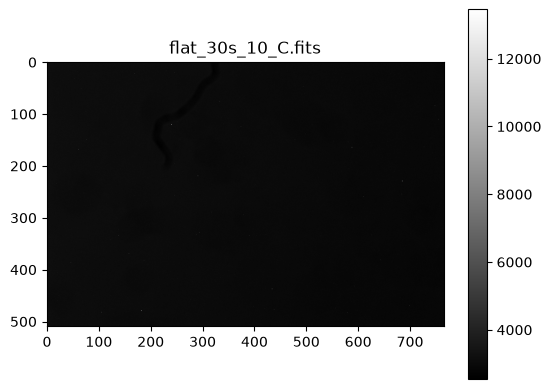

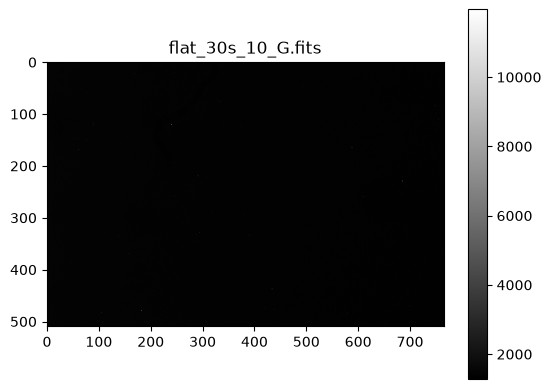

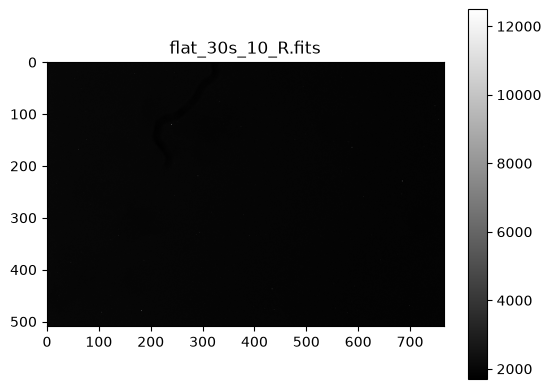

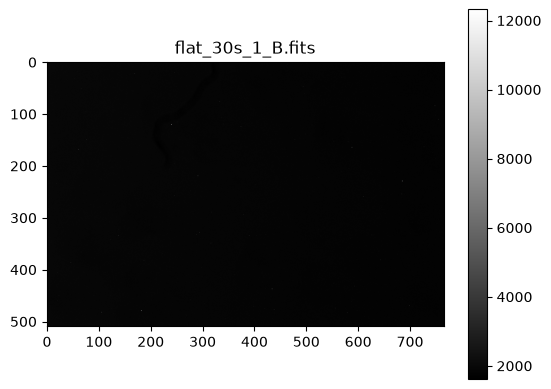

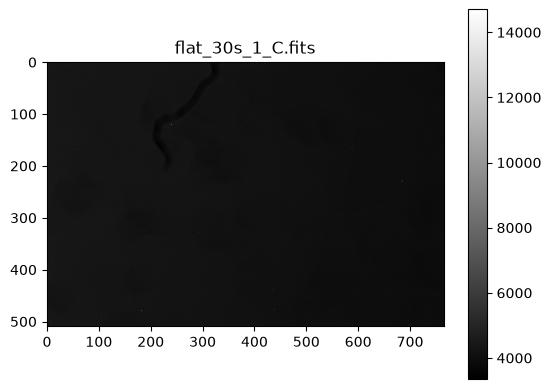

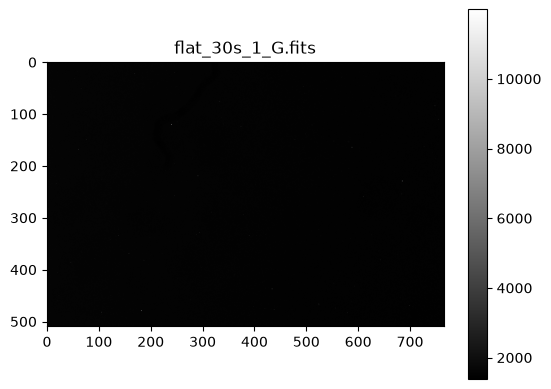

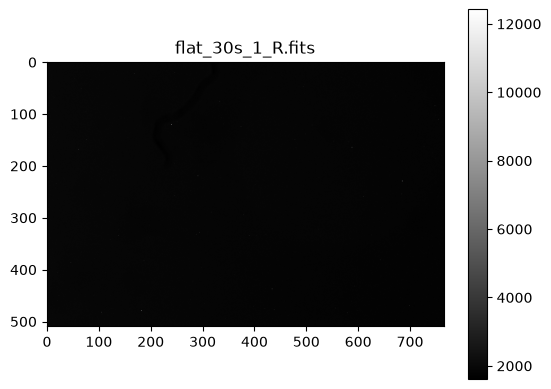

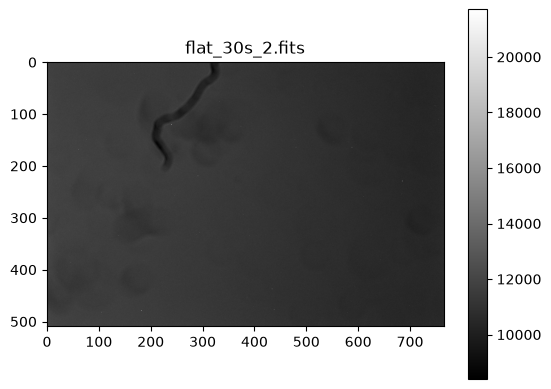

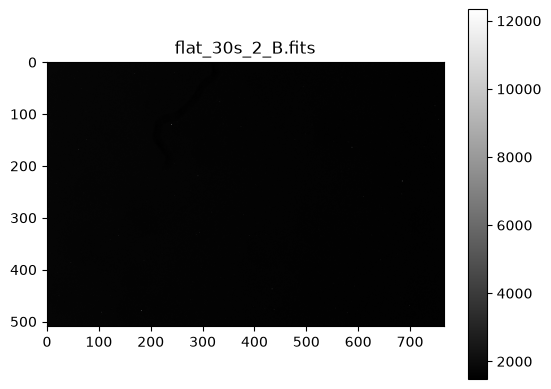

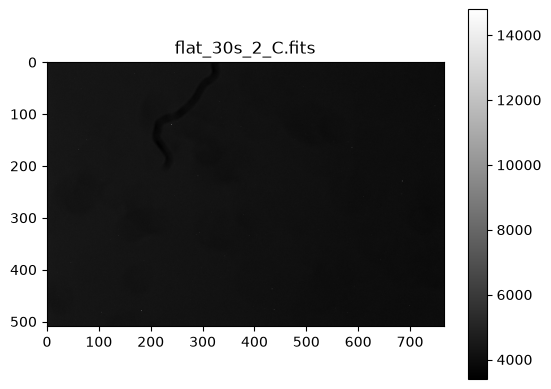

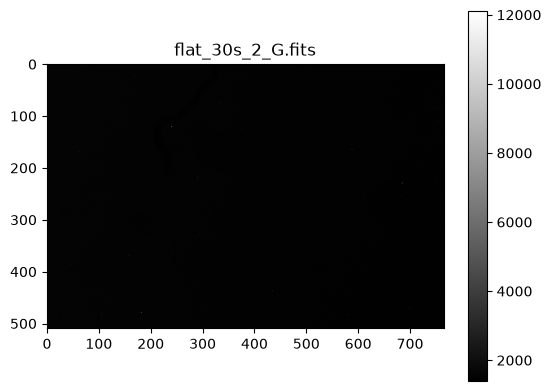

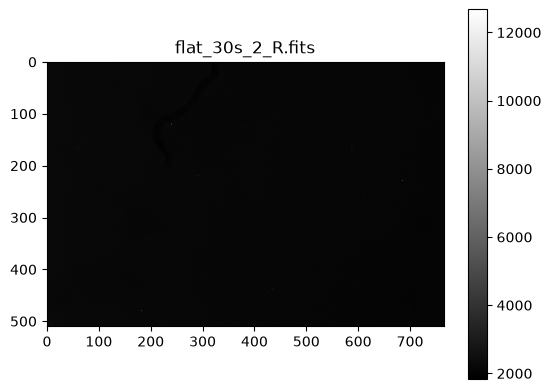

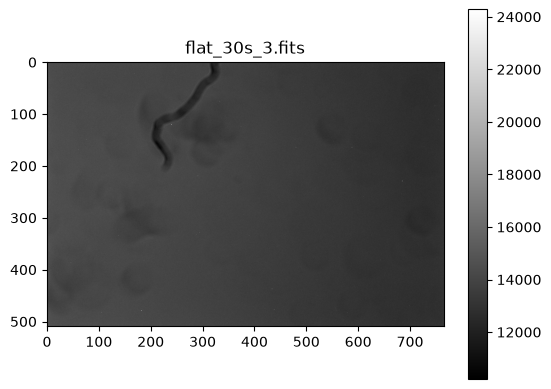

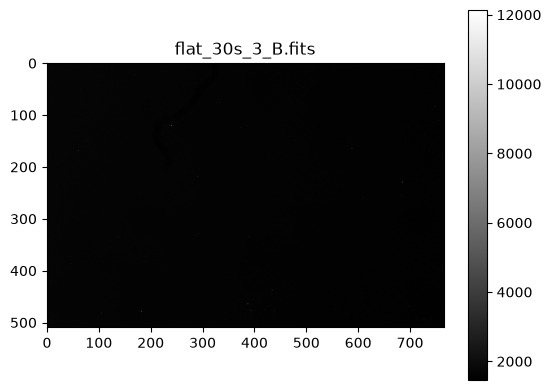

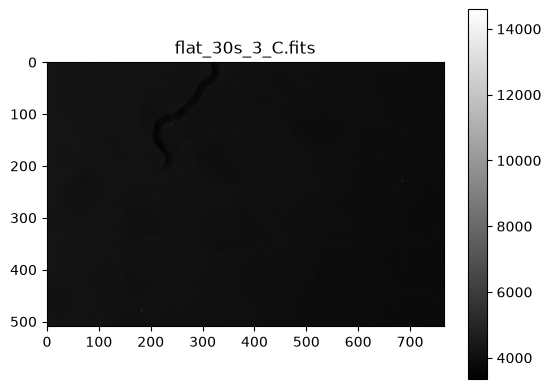

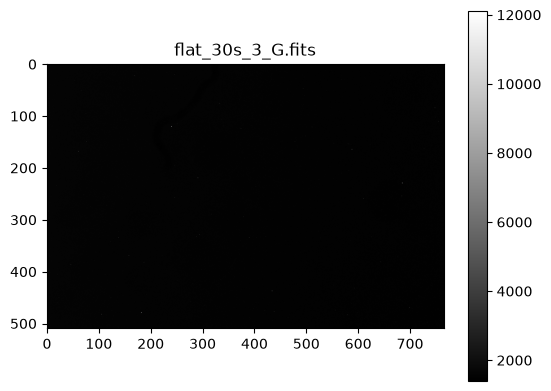

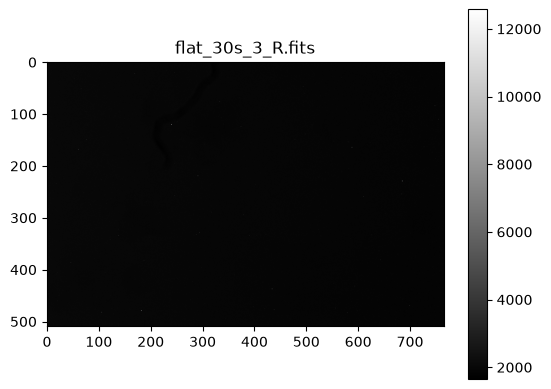

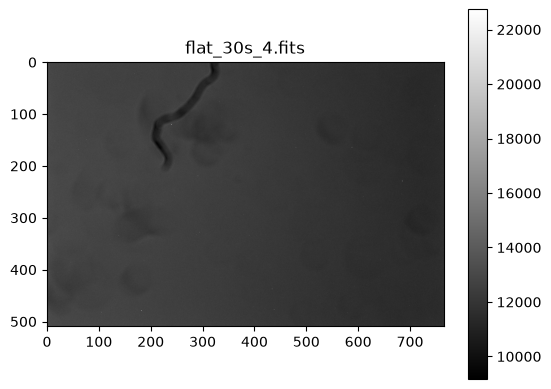

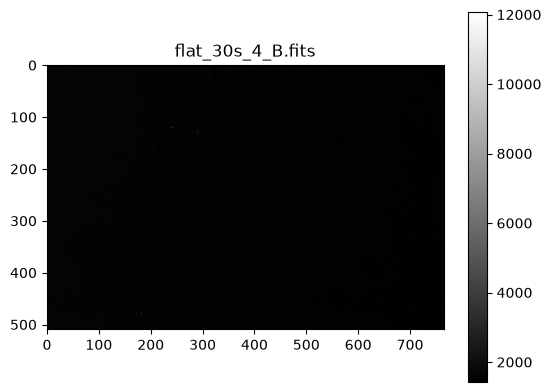

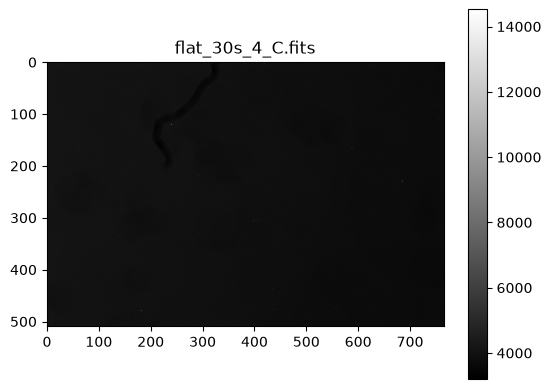

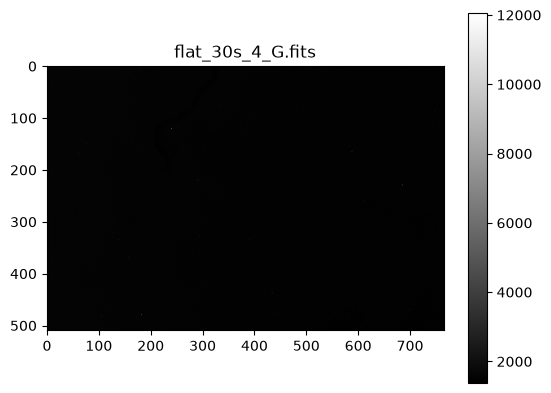

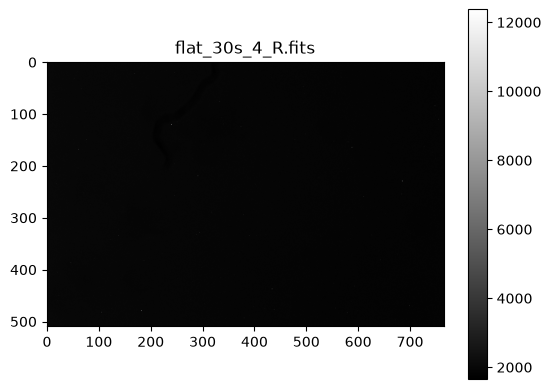

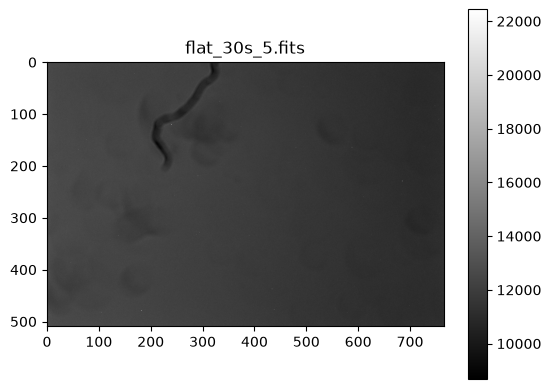

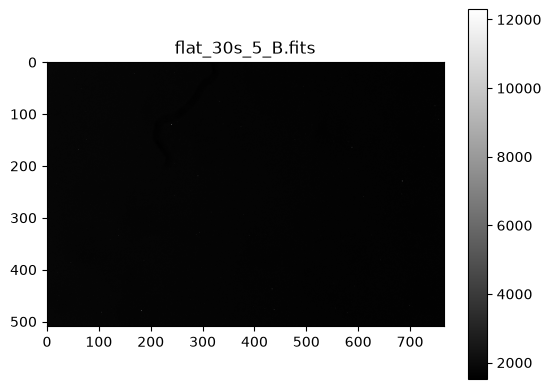

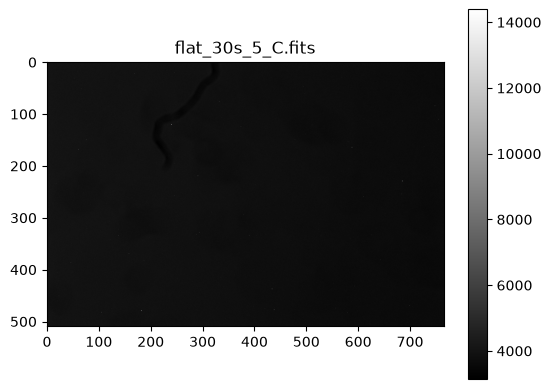

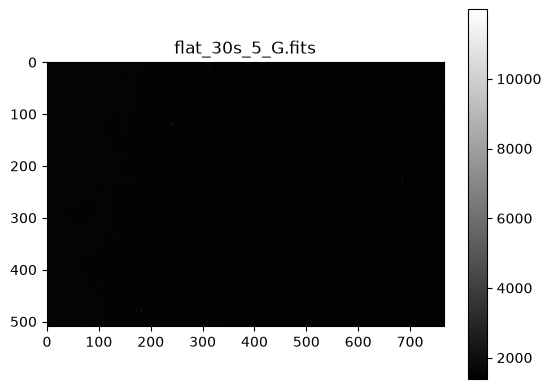

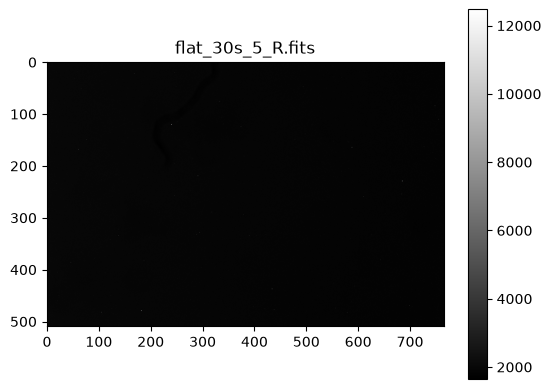

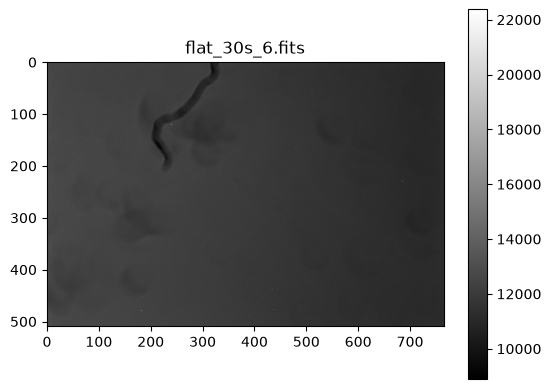

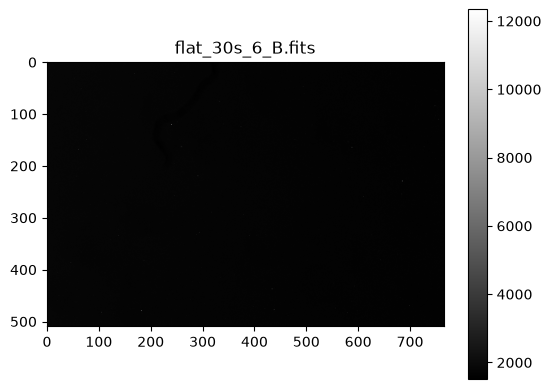

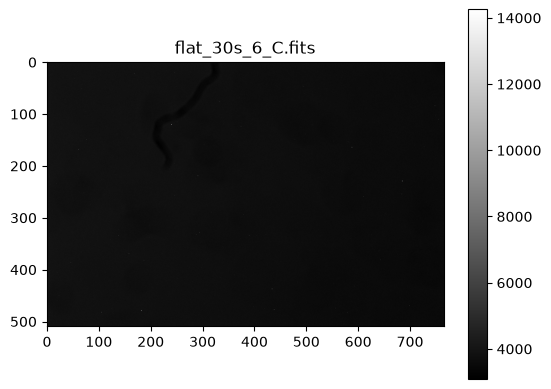

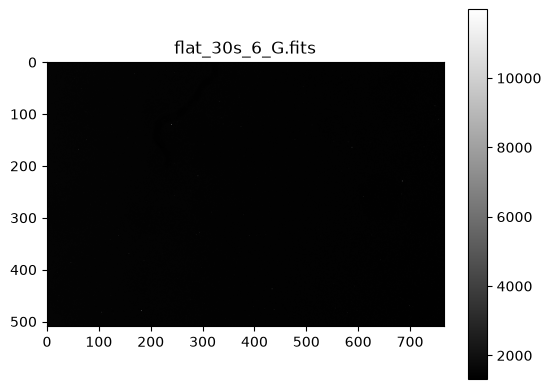

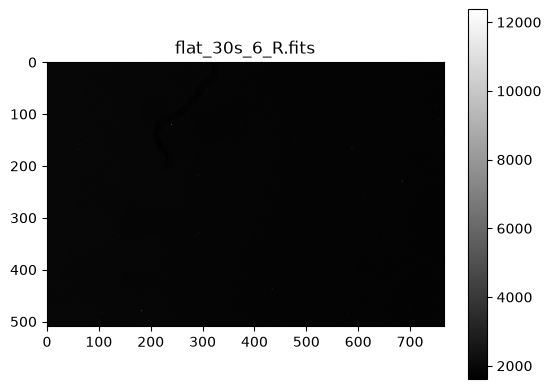

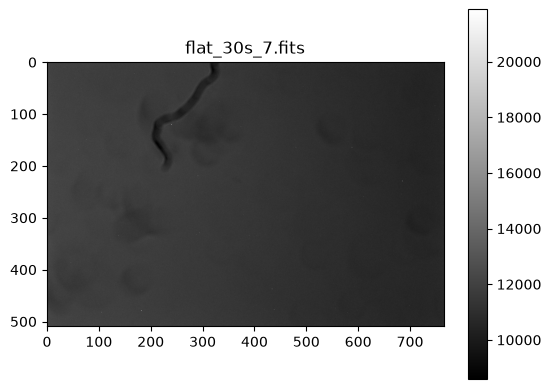

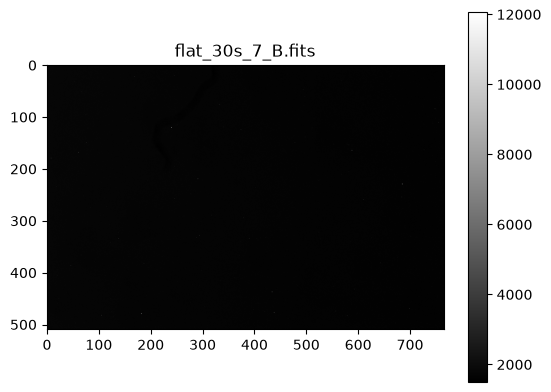

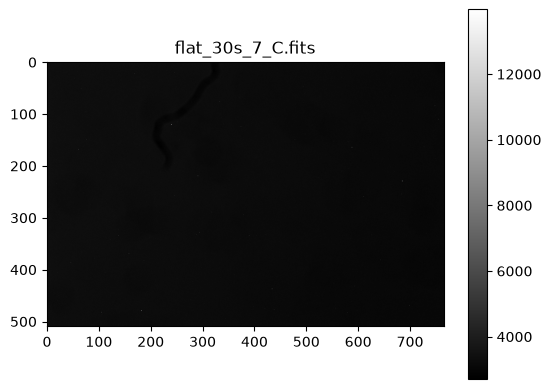

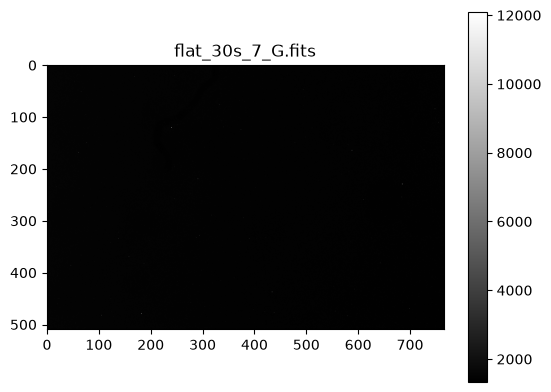

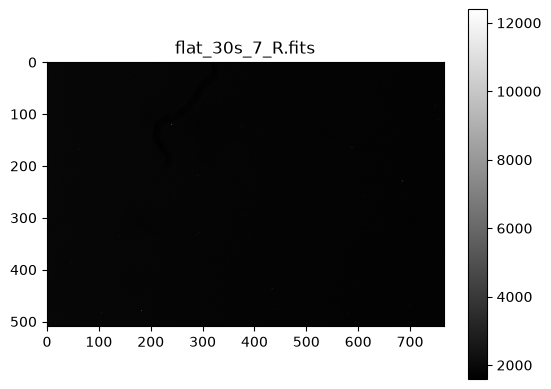

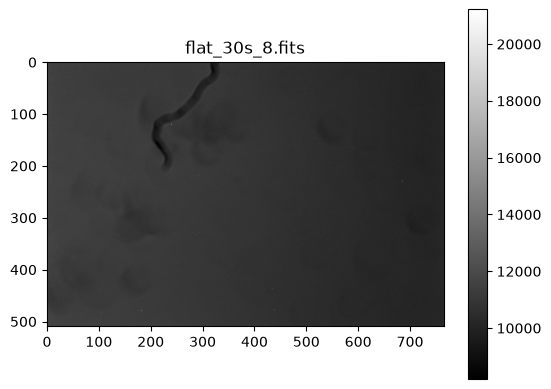

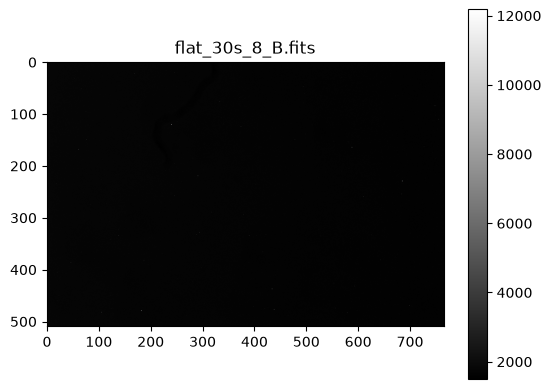

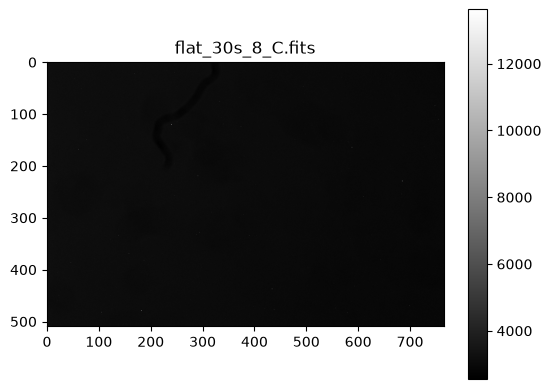

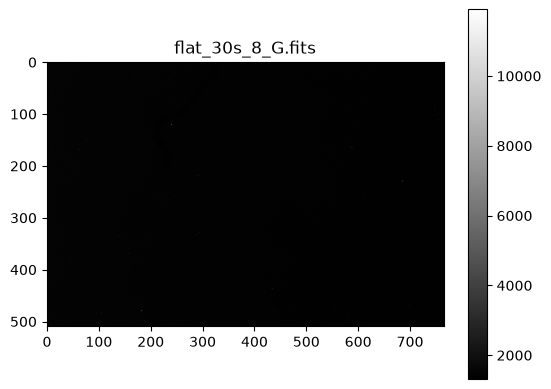

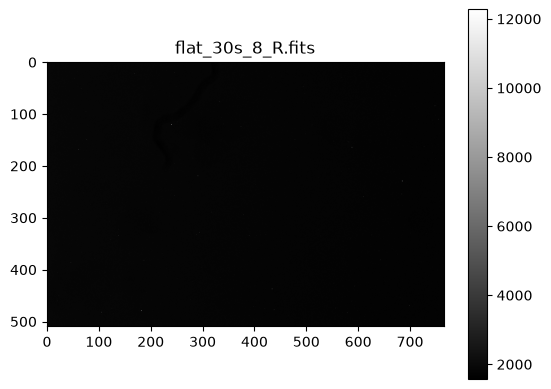

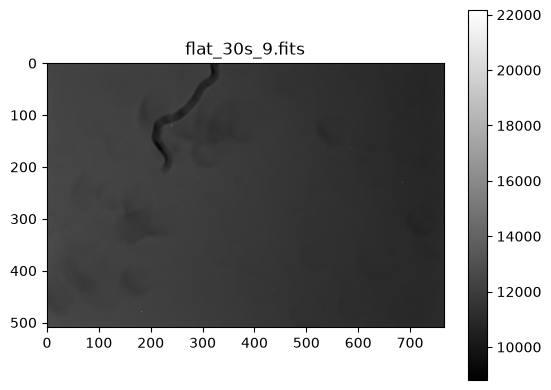

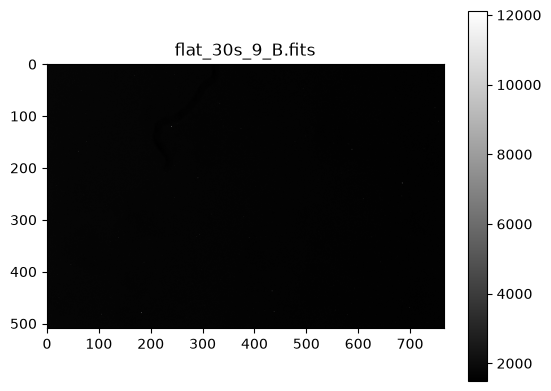

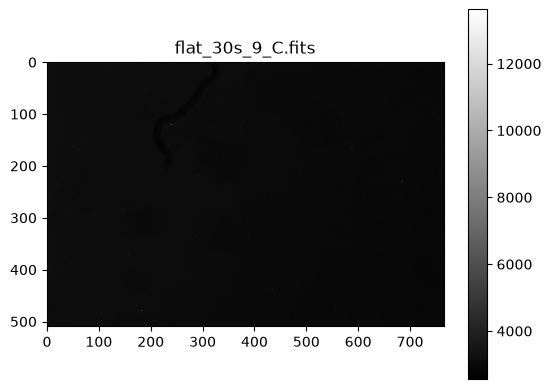

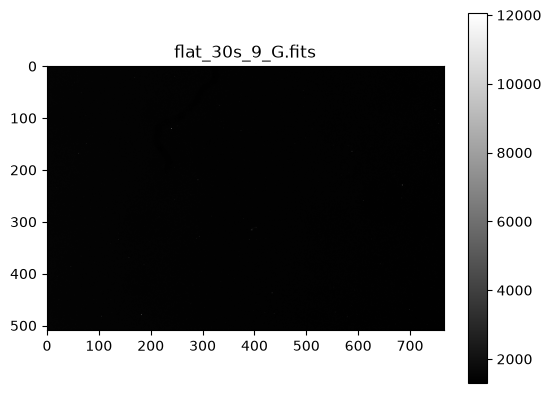

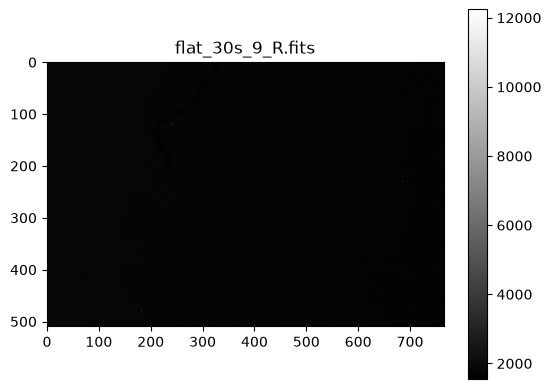

In [15]:
# open image files, check, & save
flats_array = []
for img in filepaths_flats:
    file = fits.open(img)
    file = file[0].data
    file = file.astype('int32')
    plt.figure()
    plt.imshow(file, cmap='gray')
    plt.colorbar()
    plt.title(img[5:])
    flats_array.append(file) # in images, can see thread/fibre that now seems to be on the telescope lens 
                                        # (may have to crop images post-reduction / be careful when getting counts

In [26]:
filepaths_flats_r = glob(filepath+"flat_*_r.fits") # the *new* r_filters = unlabelled [retook as light outside has changed]
filepaths_flats_r

['Data\\flat_30s_10_R.fits',
 'Data\\flat_30s_1_R.fits',
 'Data\\flat_30s_2_R.fits',
 'Data\\flat_30s_3_R.fits',
 'Data\\flat_30s_4_R.fits',
 'Data\\flat_30s_5_R.fits',
 'Data\\flat_30s_6_R.fits',
 'Data\\flat_30s_7_R.fits',
 'Data\\flat_30s_8_R.fits',
 'Data\\flat_30s_9_R.fits']

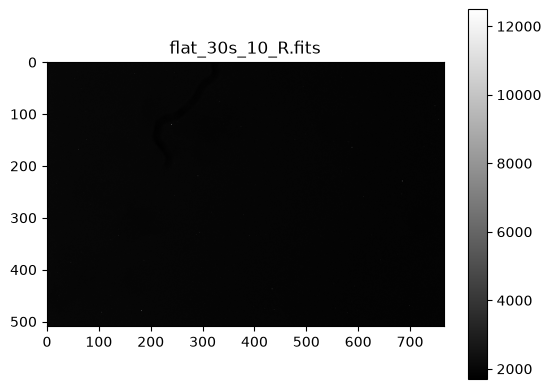

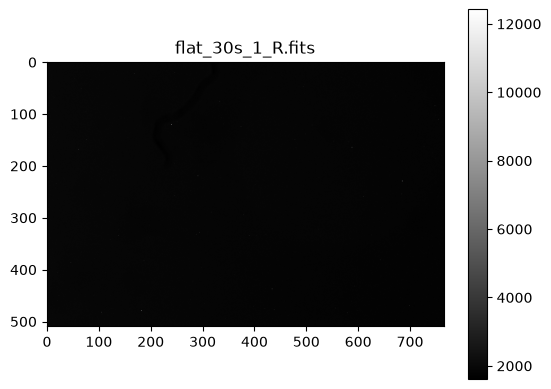

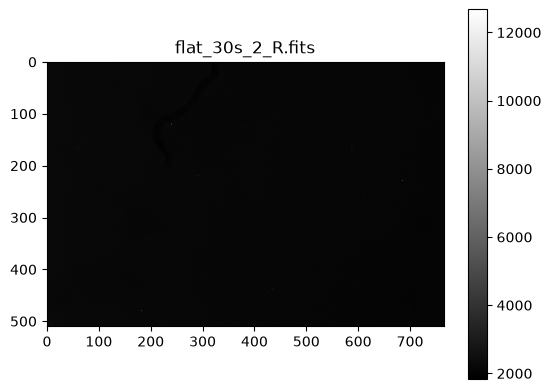

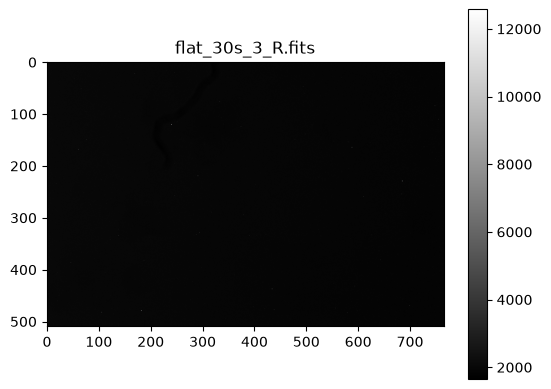

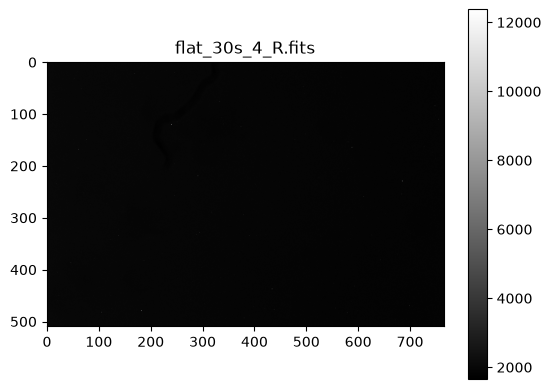

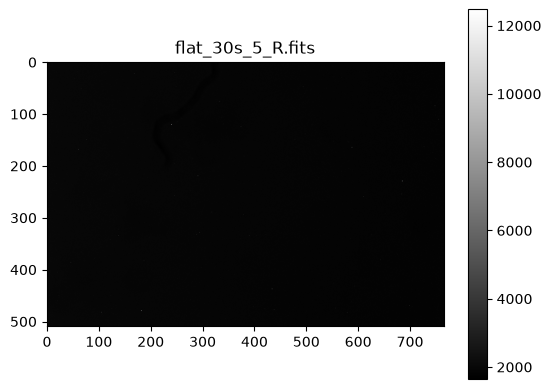

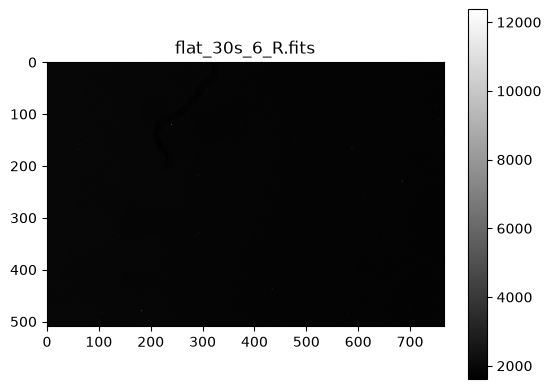

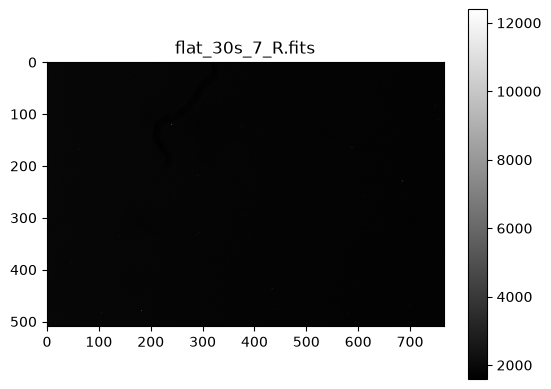

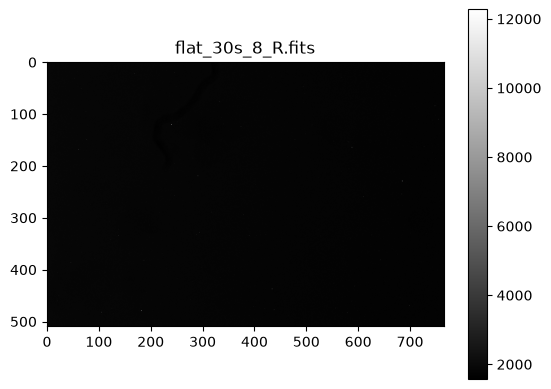

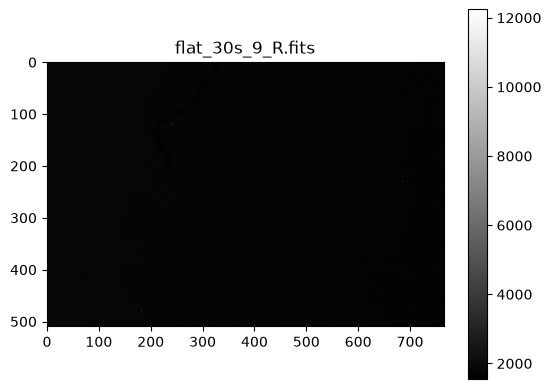

In [27]:
# open image files, check, & save
flats_array_r = []
for img in filepaths_flats_r:
    file = fits.open(img)
    file = file[0].data
    file = file.astype('int32')
    plt.figure()
    plt.imshow(file, cmap='gray')
    plt.colorbar()
    plt.title(img[5:])
    flats_array_r.append(file) 

In [28]:
filepaths_flats_b = glob(filepath+"flat_*_b.fits")
filepaths_flats_b

['Data\\flat_30s_10_B.fits',
 'Data\\flat_30s_1_B.fits',
 'Data\\flat_30s_2_B.fits',
 'Data\\flat_30s_3_B.fits',
 'Data\\flat_30s_4_B.fits',
 'Data\\flat_30s_5_B.fits',
 'Data\\flat_30s_6_B.fits',
 'Data\\flat_30s_7_B.fits',
 'Data\\flat_30s_8_B.fits',
 'Data\\flat_30s_9_B.fits']

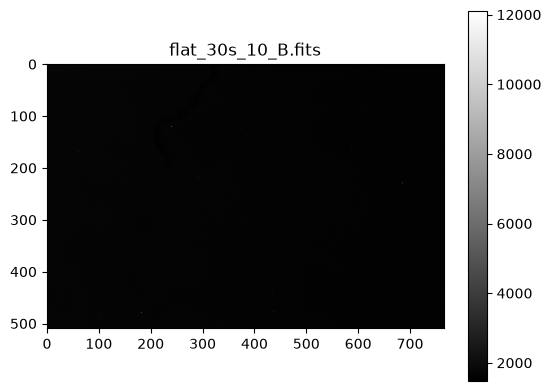

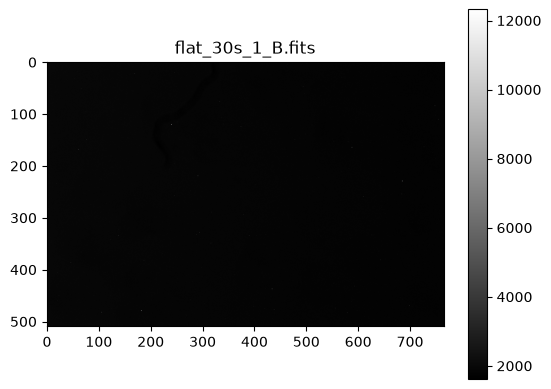

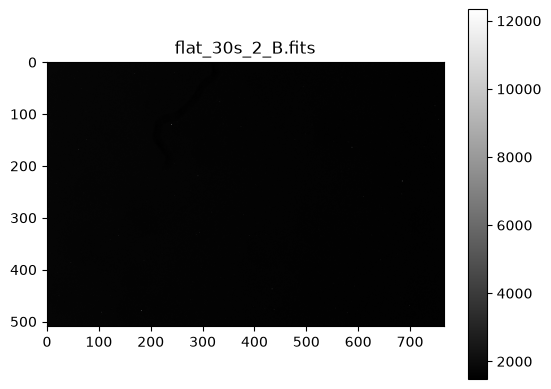

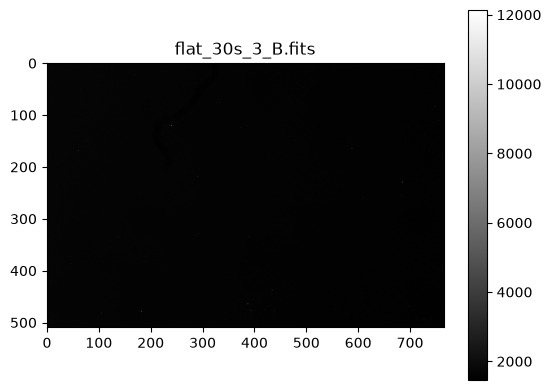

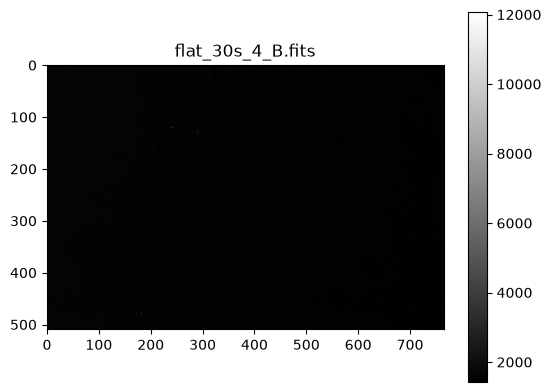

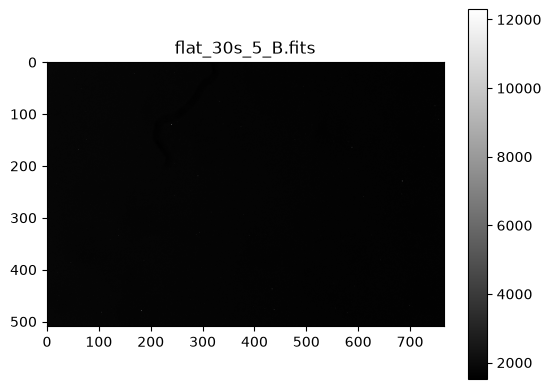

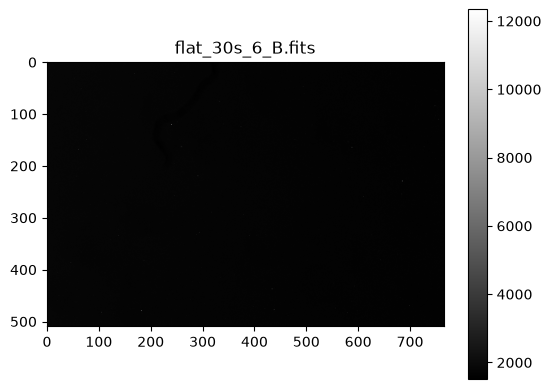

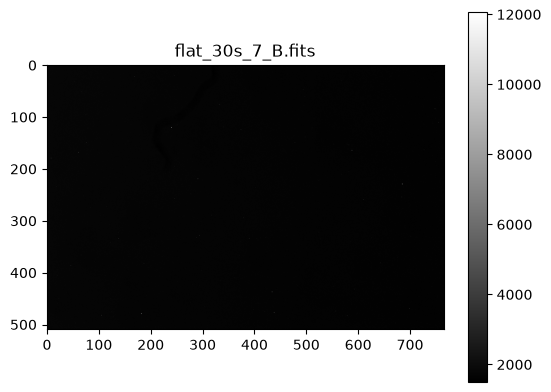

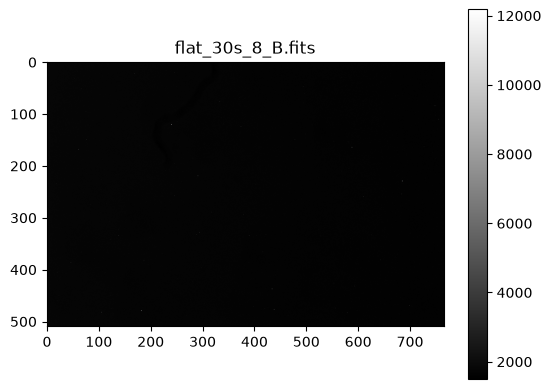

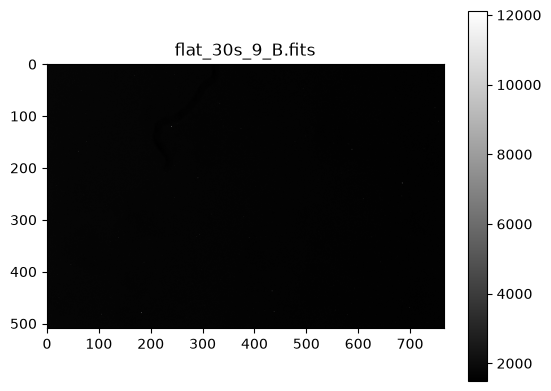

In [29]:
# open image files, check, & save
flats_array_b = []
for img in filepaths_flats_b:
    file = fits.open(img)
    file = file[0].data
    file = file.astype('int32')
    plt.figure()
    plt.imshow(file, cmap='gray')
    plt.colorbar()
    plt.title(img[5:])
    flats_array_b.append(file) 

In [30]:
filepaths_flats_g = glob(filepath+"flat_*_g.fits")
filepaths_flats_g

['Data\\flat_30s_10_G.fits',
 'Data\\flat_30s_1_G.fits',
 'Data\\flat_30s_2_G.fits',
 'Data\\flat_30s_3_G.fits',
 'Data\\flat_30s_4_G.fits',
 'Data\\flat_30s_5_G.fits',
 'Data\\flat_30s_6_G.fits',
 'Data\\flat_30s_7_G.fits',
 'Data\\flat_30s_8_G.fits',
 'Data\\flat_30s_9_G.fits']

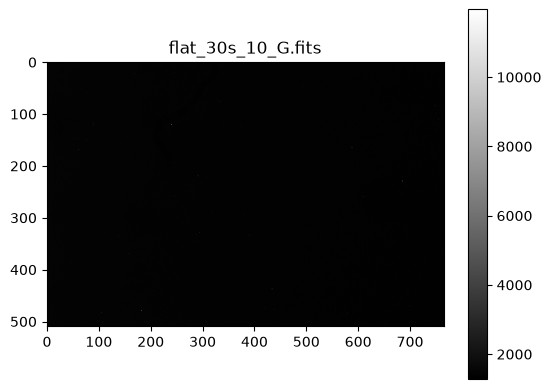

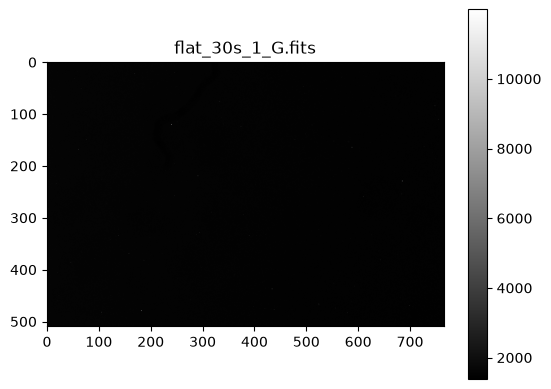

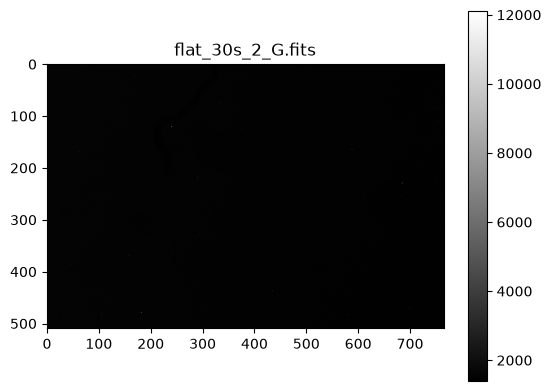

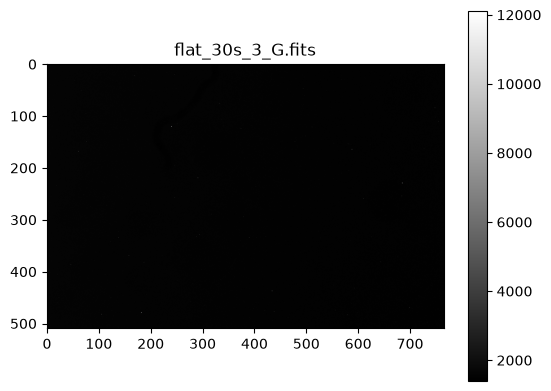

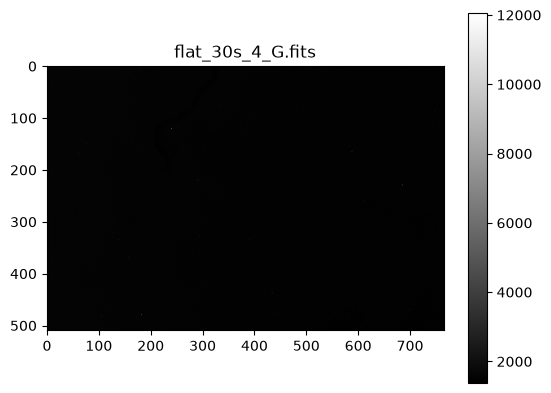

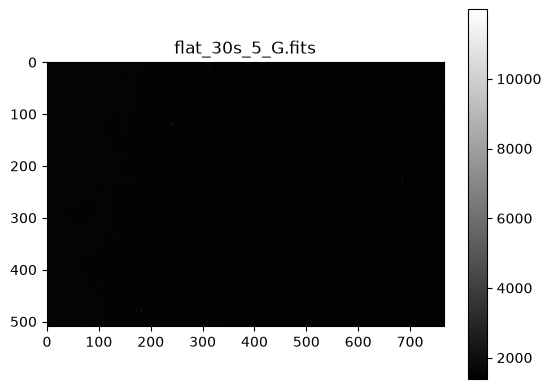

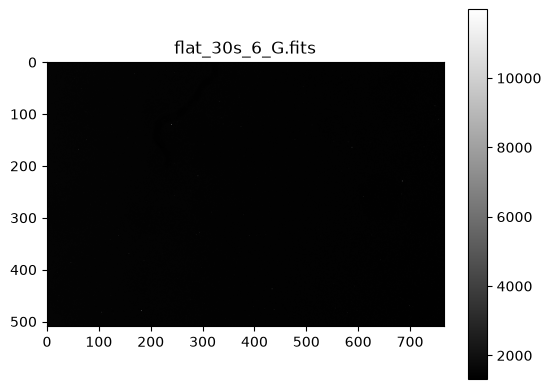

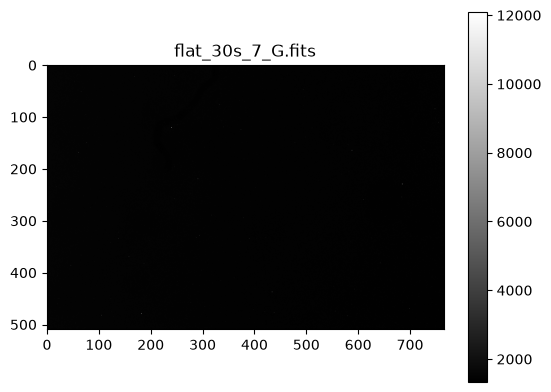

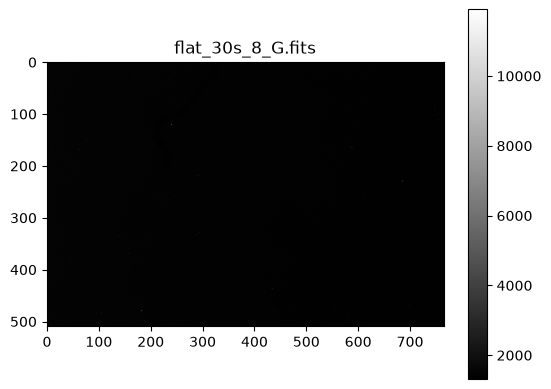

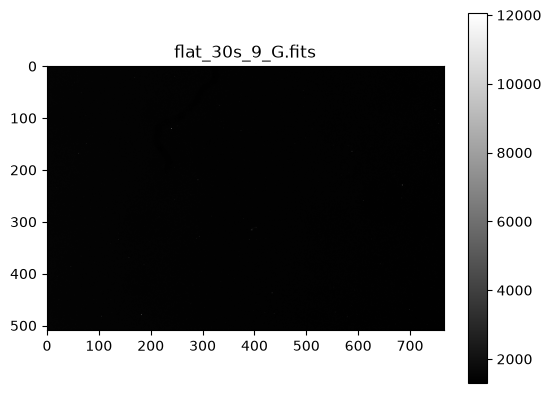

In [31]:
# open image files, check, & save
flats_array_g = []
for img in filepaths_flats_g:
    file = fits.open(img)
    file = file[0].data
    file = file.astype('int32')
    plt.figure()
    plt.imshow(file, cmap='gray')
    plt.colorbar()
    plt.title(img[5:])
    flats_array_g.append(file) 

In [32]:
filepaths_flats_c = glob(filepath+"flat_*_c.fits")
filepaths_flats_c

['Data\\flat_30s_10_C.fits',
 'Data\\flat_30s_1_C.fits',
 'Data\\flat_30s_2_C.fits',
 'Data\\flat_30s_3_C.fits',
 'Data\\flat_30s_4_C.fits',
 'Data\\flat_30s_5_C.fits',
 'Data\\flat_30s_6_C.fits',
 'Data\\flat_30s_7_C.fits',
 'Data\\flat_30s_8_C.fits',
 'Data\\flat_30s_9_C.fits']

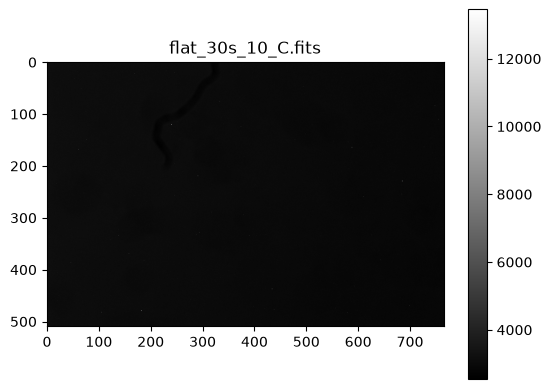

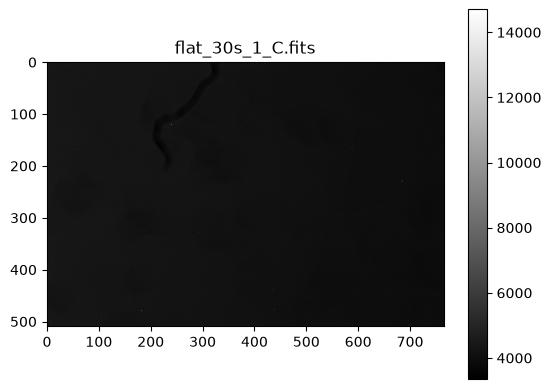

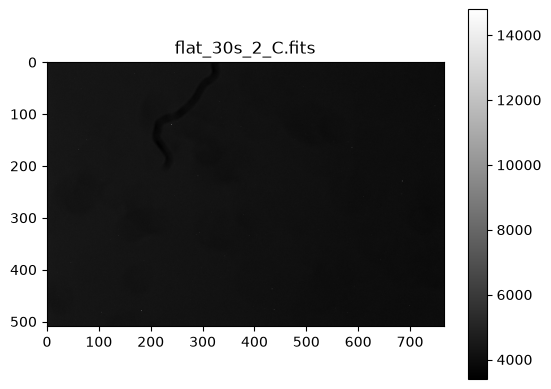

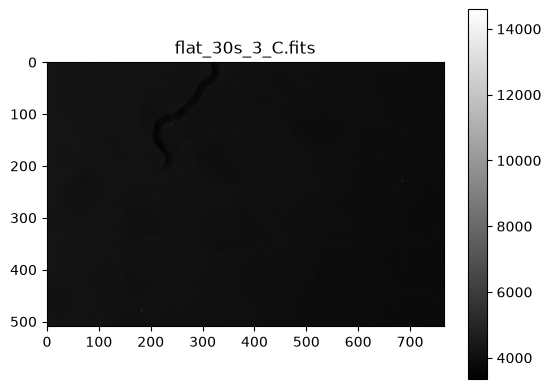

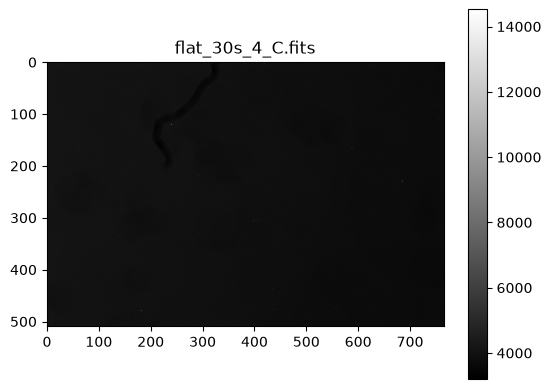

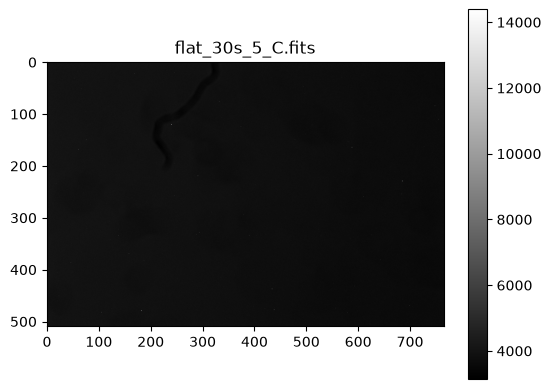

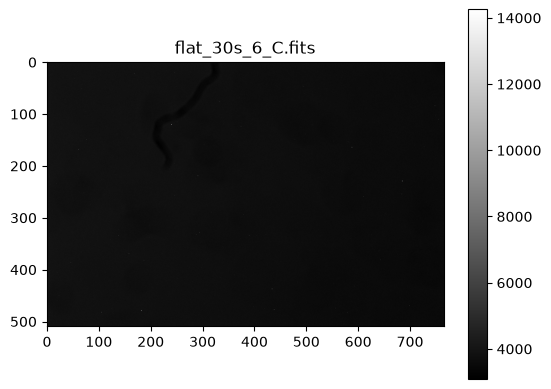

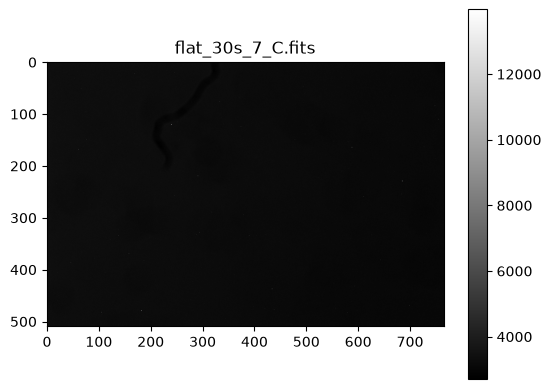

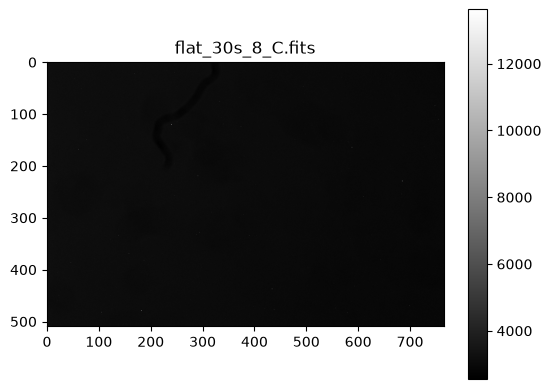

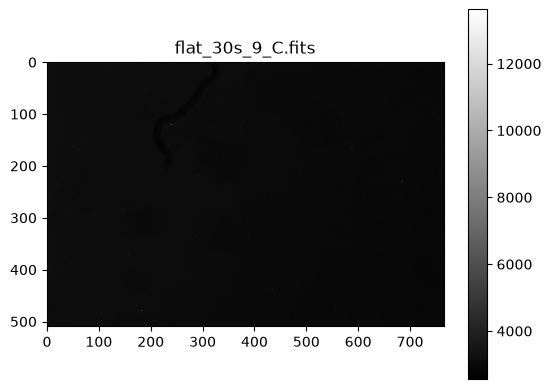

In [33]:
# open image files, check, & save
flats_array_c = []
for img in filepaths_flats_c:
    file = fits.open(img)
    file = file[0].data
    file = file.astype('int32')
    plt.figure()
    plt.imshow(file, cmap='gray')
    plt.colorbar()
    plt.title(img[5:])
    flats_array_c.append(file) 

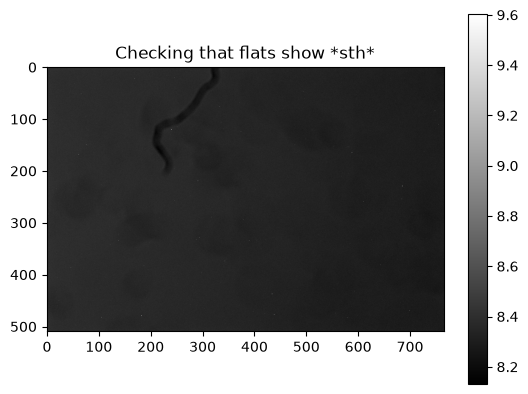

In [34]:
plt.figure()
plt.imshow(np.log(flats_array_c[2]), cmap='gray')
plt.colorbar()
plt.title("Checking that flats show *sth*"); # so the thread does show up when the looking at img in log scale

## Reduce the FITS files [calibrating the images]

<u>Processing:<u>
- [Throughout this, we're using the darks as a combination of biases & darks [*all images* taken for 30s exposure)
- Take mean of multiple bias [dark] images to get the 'masterbias' [masterdark]
- Subtract masterbias [masterdark] from *each* of the flats,
    - ~also subtract the masterdark? [exposure time = important ...]~
    - THEN combine & normalise (by dividing by the average pixel value in the centre of the array/the "field of view")
- reduced science image = $\frac{[\text{science image - masterflat}]}{\text{normalised masterflat}}$

#### Creating the master files for data reduction

In [64]:
# create masterdark / masterbias
master_dark = np.mean(darks_array, axis=0)
newHeader_dark = fits.PrimaryHDU(master_dark)
newHeader_dark.writeto(filepath+"master_dark.fits")
    #"C:/Users/nowar/Documents/GitHub/3rd-Year-Labs/Exp 2 CCDs & Spectroscopy/data/master_dark.fits")

(510, 765)


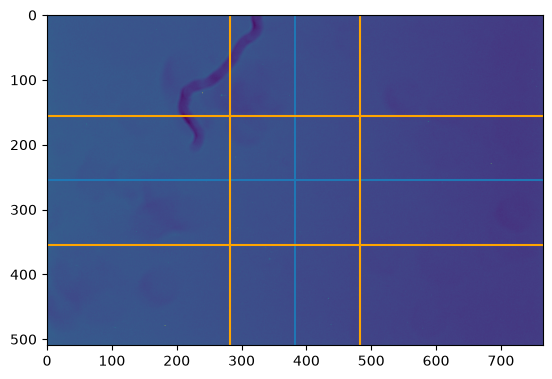

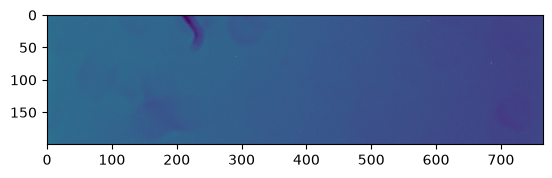

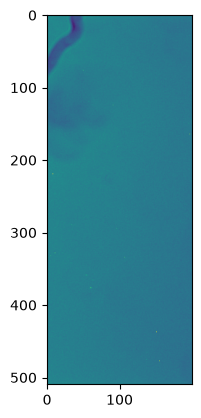

In [75]:
# will have to normalise by "avg pixel value in centre of array"
plt.imshow(flats_array[0]);
print(np.shape(flats_array[0]))
plt.axhline(255)
plt.axvline(382.5);
## now do lines marking ~ the box we'll take as the 'centre' => 1st starting w/ central 200x200 box
plt.axhline(155, color='orange')
plt.axvline(282.5, color='orange');
plt.axhline(355, color='orange')
plt.axvline(482.5, color='orange');

plt.figure()
plt.imshow(flats_array[0][155:355,:]);

plt.figure()
plt.imshow(flats_array[0][:,283:483]);

##=> so want to take central cut using: [155:355+1,283:483+1] (adding "+1" as slicing stops right *before* the last digit)

In [39]:
flat_b_array_r = []
for flat in flats_array_r:
    bias_subtracted = flat - master_dark # using darks as combination bias + dark, 30s exposure time throughout
    flat_b_array_r.append(bias_subtracted/np.mean(bias_subtracted[155:355+1,283:483+1])) 
                # see above for why *this* central cut was chosen [should give ~ 200x200 central box]
master_flat_r = np.mean(flat_b_array_r, axis=0)
newHeader_flat_r = fits.PrimaryHDU(master_flat_r)
newHeader_flat_r.writeto(filepath+"master_flat_r.fits")    

In [40]:
# most images were taken with R filter, but also took some in B, G, C filters
flat_b_array_b = []
for flat in flats_array_b:
    bias_subtracted = flat - master_dark # using darks as combination bias + dark, 30s exposure time throughout
    flat_b_array_b.append(bias_subtracted/np.mean(bias_subtracted[155:355+1,283:483+1])) 
master_flat_b = np.mean(flat_b_array_b, axis=0)
newHeader_flat_b = fits.PrimaryHDU(master_flat_b)
newHeader_flat_b.writeto(filepath+"master_flat_b.fits")  

flat_b_array_g = []
for flat in flats_array_g:
    bias_subtracted = flat - master_dark # using darks as combination bias + dark, 30s exposure time throughout
    flat_b_array_g.append(bias_subtracted/np.mean(bias_subtracted[155:355+1,283:483+1])) 
master_flat_g = np.mean(flat_b_array_g, axis=0)
newHeader_flat_g = fits.PrimaryHDU(master_flat_g)
newHeader_flat_g.writeto(filepath+"master_flat_g.fits")    

flat_b_array_c = []
for flat in flats_array_c:
    bias_subtracted = flat - master_dark # using darks as combination bias + dark, 30s exposure time throughout
    flat_b_array_c.append(bias_subtracted/np.mean(bias_subtracted[155:355+1,283:483+1])) 
master_flat_c = np.mean(flat_b_array_c, axis=0)
newHeader_flat_c = fits.PrimaryHDU(master_flat_c)
newHeader_flat_c.writeto(filepath+"master_flat_c.fits")    

#### Reducing the Science Images

In [36]:
# now can open back up the files if need to re-reduce
master_dark_fits = fits.open(filepath+"master_dark.fits")  #masterdark doubles as masterbias
master_dark = master_dark_fits[0].data

In [41]:
master_flat_r = fits.open(filepath+"master_flat_r.fits") # now can open back up the files if need to re-reduce
master_flat_r_data = master_flat_r[0].data
# most of our images were taken with the R filter, but some were taken with the B, G, C filters
master_flat_b = fits.open(filepath+"master_flat_b.fits")
master_flat_b_data = master_flat_b[0].data
master_flat_g = fits.open(filepath+"master_flat_g.fits")
master_flat_g_data = master_flat_g[0].data
master_flat_c = fits.open(filepath+"master_flat_c.fits")
master_flat_c_data = master_flat_c[0].data

In [47]:
# then create the reduced files for the obs1 data
print(filepaths_obs1) # # obs1_array, filepaths_obs1
filepaths_obs1[0].split('\\')

['Data\\obs1_star1_app1_30s.fits', 'Data\\obs1_star1_app2_30s.fits', 'Data\\obs1_star1_app3_30s.fits', 'Data\\obs1_star1_app4_30s_B.fits', 'Data\\obs1_star1_app4_30s_C.fits', 'Data\\obs1_star1_app4_30s_G.fits', 'Data\\obs1_star1_app4_30s_R.fits']


['Data', 'obs1_star1_app1_30s.fits']

In [78]:
def reduce_images(raw_array, master_bias, master_flat, filenames, headers, extraLabel=''):
    reduced_array = []
    i = 0
    for raw in raw_array:
        reduced_image = (raw - master_bias) / master_flat
        reduced_array.append(reduced_image)
        
        oldName1, oldName2 = filenames[i].split('\\')  # where oldName2 is the actual filename
       # oldName_bits = oldName1.split('/') #& oldName1 , & then oldName_bits give the location (subfolders)
        newName = "data/reduced/fb_"+str(extraLabel)+str(oldName2)
        print(newName)
        fits.writeto(newName, reduced_image, headers[i], output_verify='fix', overwrite=True)
        i+=1
    return reduced_array

In [79]:
# images done with R filter = indices [0 up to & incl 2] [6]
#print(filepaths_obs1[0:3], filepaths_obs1[6])
filepaths_obs1_Rfilter = filepaths_obs1[0:3]#.append(str(filepaths_obs1[6]))
filepaths_obs1_Rfilter.append(filepaths_obs1[6])
print(filepaths_obs1_Rfilter)
orig_obs1_Rfilter = obs1_array[0:3]#.append(str(filepaths_obs1[6]))
orig_obs1_Rfilter.append(obs1_array[6])
obs1_headers_Rfilter = obs1_headers_list[0:3]
obs1_headers_Rfilter.append(obs1_headers_list[6])

obs1_Rfilt_array = reduce_images(raw_array=orig_obs1_Rfilter, master_bias=master_dark, master_flat=master_flat_r_data, 
                                   filenames=filepaths_obs1_Rfilter, headers=obs1_headers_Rfilter, extraLabel='Rfilt_')

['Data\\obs1_star1_app1_30s.fits', 'Data\\obs1_star1_app2_30s.fits', 'Data\\obs1_star1_app3_30s.fits', 'Data\\obs1_star1_app4_30s_R.fits']
data/reduced/fb_Rfilt_obs1_star1_app1_30s.fits
data/reduced/fb_Rfilt_obs1_star1_app2_30s.fits
data/reduced/fb_Rfilt_obs1_star1_app3_30s.fits
data/reduced/fb_Rfilt_obs1_star1_app4_30s_R.fits


In [99]:
[[obs1_headers_list[3]]]

[[SIMPLE  =                    T / Fits standard                                  
  BITPIX  =                   16 / number of bits per data pixel                  
  NAXIS   =                    2 / number of data axes                            
  NAXIS1  =                  765 / length of data axis 1                          
  NAXIS2  =                  510 / length of data axis 2                          
  EXTEND  =                    T / FITS dataset may contain extensions            
  COMMENT   FITS (Flexible Image Transport System) format is defined in 'Astronomy
  COMMENT   and Astrophysics', volume 376, page 359; bibcode: 2001A&A...376..359H 
  BZERO   =                32768 / offset data range to that of unsigned short    
  BSCALE  =                    1 / default scaling factor                         
  INSTRUME= 'SBIG ST402'         / Image CCD                                      
  EXPTIME =                  30. / exposure time (seconds)                        
  DA

In [100]:
# reduced with *other* filters
    # B filter
print('B filter, index 3:', filepaths_obs1[3])
obs1_Bfilt_array = reduce_images(raw_array=np.array([obs1_array[3]]), master_bias=master_dark, 
                                 master_flat=master_flat_b_data, filenames=[filepaths_obs1[3]],
                                 headers=[obs1_headers_list[3]], extraLabel='Bfilt_')
    # G filter
print('G filter, index 5:', filepaths_obs1[5])
obs1_Gfilt_array = reduce_images(raw_array=np.array([obs1_array[5]]), master_bias=master_dark, 
                                 master_flat=master_flat_g_data, filenames=[filepaths_obs1[5]], 
                                 headers=[obs1_headers_list[5]], extraLabel='Gfilt_')
    # C filter
print('C filter, index 4:', filepaths_obs1[4])
obs1_Cfilt_array = reduce_images(raw_array=np.array([obs1_array[4]]), master_bias=master_dark, 
                                 master_flat=master_flat_c_data, filenames=[filepaths_obs1[4]], 
                                 headers=[obs1_headers_list[4]], extraLabel='Cfilt_')

B filter, index 3: Data\obs1_star1_app4_30s_B.fits
data/reduced/fb_Bfilt_obs1_star1_app4_30s_B.fits
G filter, index 5: Data\obs1_star1_app4_30s_G.fits
data/reduced/fb_Gfilt_obs1_star1_app4_30s_G.fits
C filter, index 4: Data\obs1_star1_app4_30s_C.fits
data/reduced/fb_Cfilt_obs1_star1_app4_30s_C.fits


## Reduced Science Camera Images [for Import]

In [161]:
filepath = "Data/" # directory data files are in, can be altered 
filepaths_fb_obs1 = glob(filepath+"reduced/*obs1_*.fits")
filepaths_fb_obs1

['Data/reduced\\fb_Bfilt_obs1_star1_app4_30s_B.fits',
 'Data/reduced\\fb_Cfilt_obs1_star1_app4_30s_C.fits',
 'Data/reduced\\fb_Gfilt_obs1_star1_app4_30s_G.fits',
 'Data/reduced\\fb_Rfilt_obs1_star1_app1_30s.fits',
 'Data/reduced\\fb_Rfilt_obs1_star1_app2_30s.fits',
 'Data/reduced\\fb_Rfilt_obs1_star1_app3_30s.fits',
 'Data/reduced\\fb_Rfilt_obs1_star1_app4_30s_R.fits']

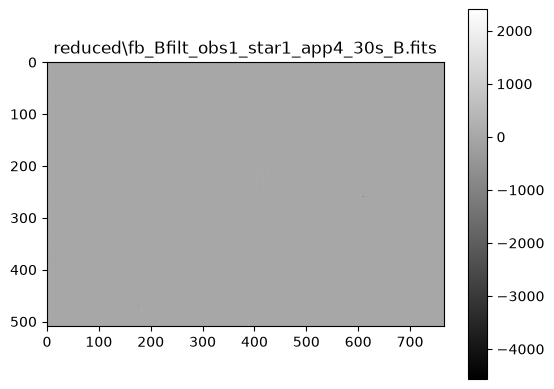

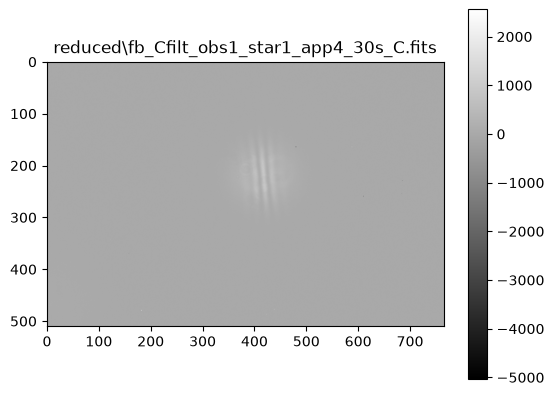

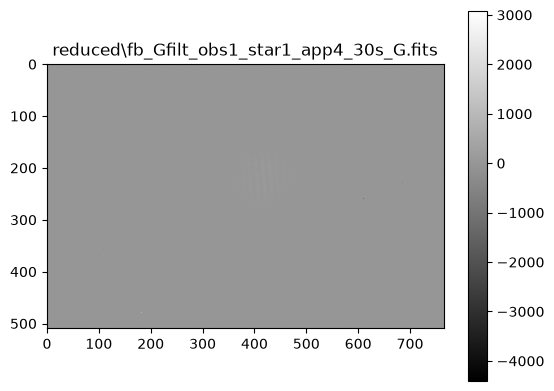

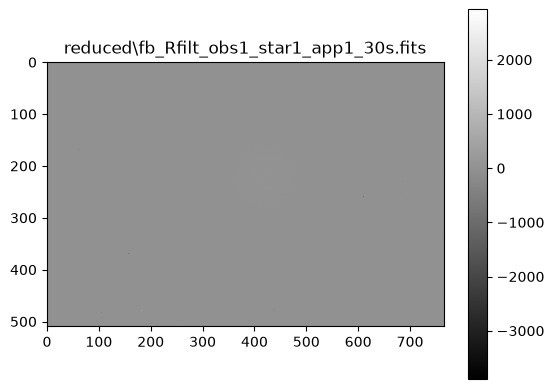

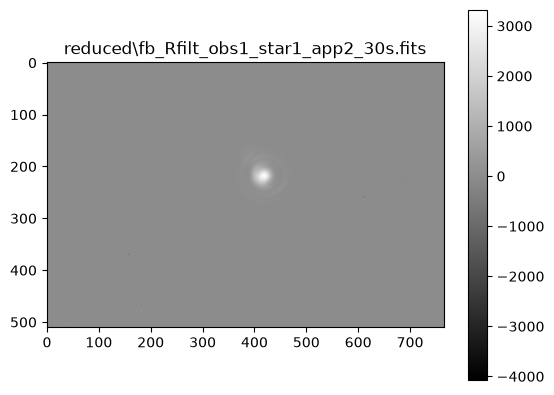

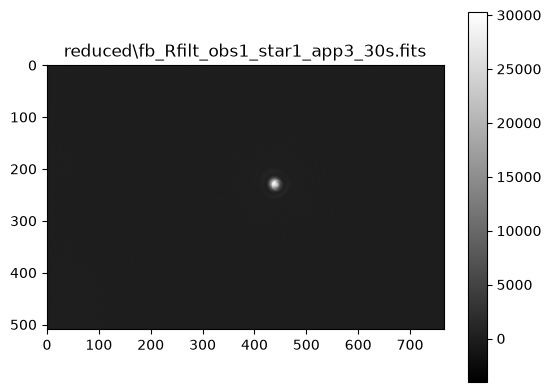

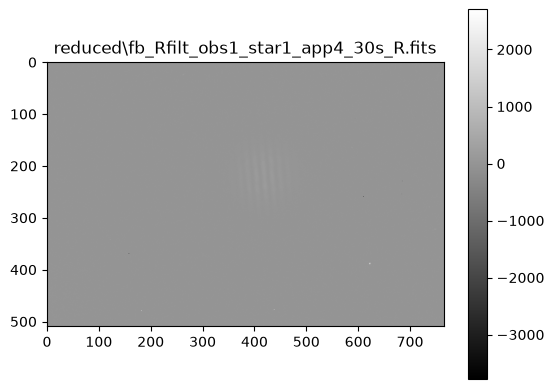

In [162]:
# open image files, check, & save
obs1_fb_array, obs1_fb_headers_list = [], []
for file_fb in filepaths_fb_obs1:
    file = fits.open(file_fb)
    obs1_fb_headers_list.append(file[0].header)
    #file = file[0].data
    #file = file.astype('int32')
    img = (file[0].data).astype('int32')
    obs1_fb_array.append(img)
    plt.figure()
    plt.imshow(img, cmap='gray') # file, cmap='gray')
    plt.colorbar()
    plt.title(file_fb[5:])
   # obs1_fb_array.append(file)

## Setting up common variables

In [4]:
# "spectral band [for lamp used throughout] = 630 ± 50 nm
lamp_lambda=0.63 # wavelength of the lamp used in micrometre [mu m]
err_lamp_lambda=0.05 # uncertainty on the wavelength of the lamp used in micrometre [mu m]


# Section 10.2 "First Observations" Data Analysis

In [163]:
# FITS files are saved in obs1_array, with the filenames available from filepaths_obs1 [6:]
for i, (filename, reduced_filename) in enumerate(zip(filepaths_obs1, filepaths_fb_obs1)):
    print(f'At index {i}:', filename[5:], '-->', reduced_filename[13:])

At index 0: obs1_star1_app1_30s.fits --> fb_Bfilt_obs1_star1_app4_30s_B.fits
At index 1: obs1_star1_app2_30s.fits --> fb_Cfilt_obs1_star1_app4_30s_C.fits
At index 2: obs1_star1_app3_30s.fits --> fb_Gfilt_obs1_star1_app4_30s_G.fits
At index 3: obs1_star1_app4_30s_B.fits --> fb_Rfilt_obs1_star1_app1_30s.fits
At index 4: obs1_star1_app4_30s_C.fits --> fb_Rfilt_obs1_star1_app2_30s.fits
At index 5: obs1_star1_app4_30s_G.fits --> fb_Rfilt_obs1_star1_app3_30s.fits
At index 6: obs1_star1_app4_30s_R.fits --> fb_Rfilt_obs1_star1_app4_30s_R.fits


In [164]:
img_obs1_star1_a = obs1_array[2] # apperture mask = at position 3 = 5mm 
img_obs1_star1_b = obs1_array[0] # apperture mask = at position 1 = 1mm 
img_obs1_star1_c = obs1_array[1] # apperture mask = at position 2 = 2mm 

img_obs1_binary_R = obs1_array[6] # aperture mask @ position 4, filter = R 
img_obs1_binary_B = obs1_array[3] # aperture mask @ position 4, filter = B
img_obs1_binary_C = obs1_array[4] # aperture mask @ position 4, filter = C
img_obs1_binary_G = obs1_array[5] # aperture mask @ position 4, filter = G

In [165]:
# now switching to: obs1_fb_array
imgfb_obs1_star1_a = obs1_fb_array[5] # apperture mask = at position 3 = 5mm 
imgfb_obs1_star1_b = obs1_fb_array[3] # apperture mask = at position 1 = 1mm 
imgfb_obs1_star1_c = obs1_fb_array[4] # apperture mask = at position 2 = 2mm 

imgfb_obs1_binary_R = obs1_fb_array[6] # aperture mask @ position 4, filter = R 
imgfb_obs1_binary_B = obs1_fb_array[0] # aperture mask @ position 4, filter = B
imgfb_obs1_binary_C = obs1_fb_array[1] # aperture mask @ position 4, filter = C
imgfb_obs1_binary_G = obs1_fb_array[2] # aperture mask @ position 4, filter = G

## Task 2.1

- Lamp cover set to the single 'star' [position 1, Table 1 in manual]
- Telescope aperture mask set to [per Table 2 in manual]:
    - a) position 3 / 1 5mm-diameter aperture [=0.5cm = 0.005m]
    - b) position 1 / 1 1mm-diameter aperture [0.1cm = 0.001m]
    - c) position 2 / 1 3mm-diameter aperture [0.3cm = 0.003m]
    
For each of the images [a,b,c] [all should show an ~ Airy disk, per Fig12a in manual]:
- <b>Compute</b> the <u>angular radius</u> of the <u>Airy disk</u> (maximum to 1st dark ring)
    - for the given parameters "as discussed in Sect. 6.1"
        - "the 1st minimum of the PSF [Point Spread Function] (which produces an Airy disk) = @ $\alpha_{min} = 1.22 \frac{\lambda}{D}$ (or $\alpha_{min}/mas = 252 \frac{\lambda / \mu m}{D / m} $), with:
            - $\alpha$ in milli-arcsec [mas],
            - observing wavelength $\lambda$ in $\mu m$,
            - & the telescope diameter $D$ in $m$
        - [& the 1st minimum of the Airy pattern = the 1st dark ring in the image]
    - <b> & Compare</b> to the <u>diameter</u> in the image
        - => can measure the image coords of the maximum & the 1st dark ring <b>by</b> moving the cursor to the position & noting the pixel coordinate [presumably in SAO Image DS9 => easier if the images = reduced...]
        - pixel scale = 1.77 arcsec/pixel
        - spectral band = 630nm $\pm$ 50nm (=> assume can take as $\lambda$ => = $0.63 \pm \ 0.05\mu m$)
        - per manual [check!!], telescope has a diameter of 104mm = 10.4cm = 0.104m BUT have the __aperture mask__ in front, so using those values
            - not given uncertainty on aperture diameters => could just take as no uncertainty 

In [6]:
task2_1_apertures = 1e-3*np.array([5, 1, 3]) # multiplied by 1/1000 = 1e-3 to convert from mm to m
# corresponding to positions 3,1,2 [a,b,c]

### Computation from Theory

$\begin{equation}
\alpha_{min} = 1.22 \frac{\lambda}{D}
\end{equation}$   
where:  $\alpha_{min}$ is the    
in milli-arcsec [mas], $\lambda$ is the observing wavelength in $\mu m$, & the telescope diameter $D$ is the aperture diameter in $m$
   
and the uncertainty $\Delta \alpha_{min}$ is given from error propagation by:   
$\begin{equation}
\Delta \alpha_{min} = \alpha_{min} \sqrt{\left(\frac{\Delta \lambda}{\lambda}\right)^2 + \left(\frac{\Delta D}{D}\right)^2}
\end{equation}$   
where: ....   
[note: not given uncertainties in aperture-mask-diameteres, so settting $\Delta D$ to 0.0m for moment]

In [7]:
def func_alpha_min(lamp_lambda=0.63, D_aperture=0.005):
    """alpha_min = 1.22 * lambda / D
    where alpha_min = in milli-arcsec [mas], lambda = in micrometres [mu m = 10^-3 nm], 
    & D = telescope diameter/diameter of the aperture mask in metres [m].
    """

    alpha_min = 1.22*lamp_lambda/D_aperture
    
    return alpha_min

def func_err_alpha_min(err_lamp_lambda=0.05, err_D_aperture=0.0, lamp_lambda=0.63, D_aperture=0.005):
    """err_alpha_min = alpha_min * sqrt( (err_lambda/lambda)^2 + (err_D/D)^2 )
    Following assumption that there are no uncertainties for D [have been given none], err_D is set to zero by default. """
    alpha_min = func_alpha_min(lamp_lambda=lamp_lambda, D_aperture=D_aperture)
    err_alpha_min = alpha_min*np.sqrt( (err_lamp_lambda/lamp_lambda)**2 + (err_D_aperture/D_aperture)**2 )
    return err_alpha_min
    

In [8]:
task2_1_alpha_min = func_alpha_min(D_aperture=task2_1_apertures)
task2_1_err_alpha_min = func_err_alpha_min(D_aperture=task2_1_apertures)
for i, aperture in enumerate(task2_1_apertures):
    print(f"{aperture}: alpha_min = {task2_1_alpha_min[i]} ± {task2_1_err_alpha_min[i]} milli arcsec")
    print(f"                 = {task2_1_alpha_min[i]:.0f} ± {task2_1_err_alpha_min[i]:.2g} milli arcsec")

0.005: alpha_min = 153.72 ± 12.200000000000001 milli arcsec
                 = 154 ± 12 milli arcsec
0.001: alpha_min = 768.5999999999999 ± 61.0 milli arcsec
                 = 769 ± 61 milli arcsec
0.003: alpha_min = 256.2 ± 20.333333333333336 milli arcsec
                 = 256 ± 20 milli arcsec


### Measurement from Data

In [3]:
# in SAOImage DS9, open image, region->circle lets you place a circle to get central coords, read off x & y coords
# distance in pixels  = sqrt( (x2-x1)^2 + (y2-y1)^2 )
    # then use fact that told: "1.77 arcsec/pixel" to convert from pixels to milli arcsec, so can compare w/theory
# uncertainty => take a [~standard] uncertainty when measuring the coords, then propagate the uncertainties through
    # asked supervisor: can just work with assumption that table values have no uncertainty unless given

def func_radius(x1, y1, x0, y0):
    """
    Want to get the distance in pixels from the [centre of] the maximum to the 1st dark ring, 
        to get the radius of the Airy disk (& then convert from pixels to angular radius).
    => Distance [in pixels]  = sqrt( (x1-x0)^2 + (y1-y0)^2 ),
    where [x0,y0] = the centre of the maximum/Airy disk & [x1,y1] = a point @the start of the 1st dark ring
    """
    radius = np.sqrt((np.asarray(x1)-np.asarray(x0))**2 + (np.asarray(y1)-np.asarray(y0))**2)
    # err_radius = 
    return radius#, err_radius
    

In [10]:
# 5mm aperture [app3, star1]:


# 1mm aperture [app1, star1]:


# 3mm aperture [app2, star1]:



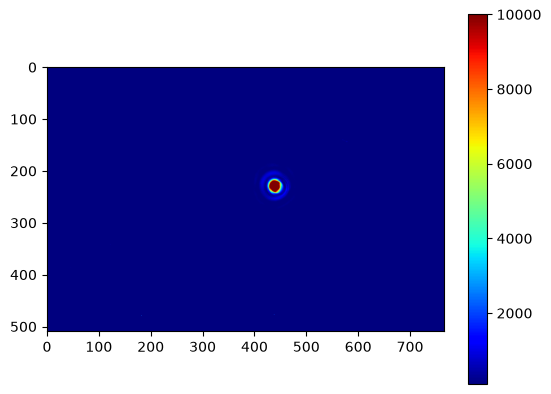

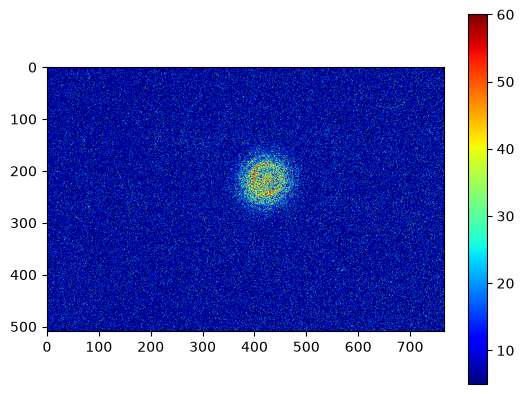

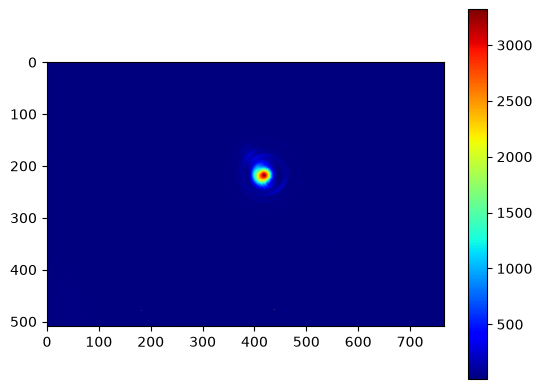

In [194]:
plt.figure()#figsize=(12,9))
plt.imshow(imgfb_obs1_star1_a, cmap='jet', vmin=100, vmax=10000)
plt.colorbar();

plt.figure()#figsize=(12,9))
plt.imshow(imgfb_obs1_star1_b, cmap='jet', vmin=5, vmax=60)
plt.colorbar();

plt.figure()#figsize=(12,9))
plt.imshow(imgfb_obs1_star1_c, cmap='jet', vmin=10)
plt.colorbar();

#### Trying 1st w/ [a: position 3, 5mm]
{v poor image quality => hard to determine rings}

##### Attempt A

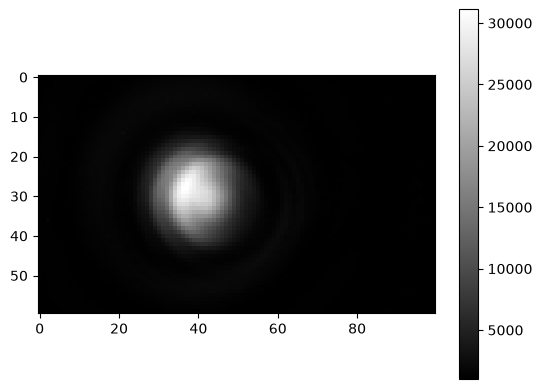

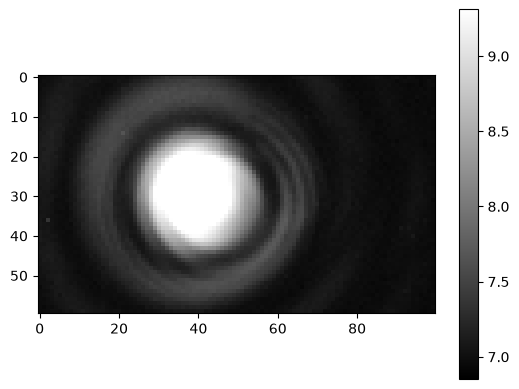

In [117]:
# try 1st w/ [a: position 3, 5mm] [ img_obs1_star1_a ]

plt.figure()#figsize=(12,9))
plt.imshow(img_obs1_star1_a[200:260,400:500], cmap='gray')
# add in to show WCS coords, etc
plt.colorbar();
#plt.title()

plt.figure()#figsize=(12,9))
plt.imshow(np.log(img_obs1_star1_a[200:260,400:500]), cmap='gray', vmax=np.max(np.log(img_obs1_star1_a[200:260,400:500]))*90/100,
          vmin=np.min(np.log(img_obs1_star1_a[200:260,400:500]))*99/100)
# add in to show WCS coords, etc
plt.colorbar();
#plt.title()

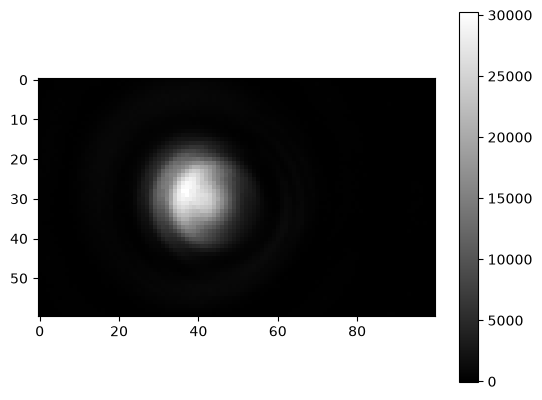

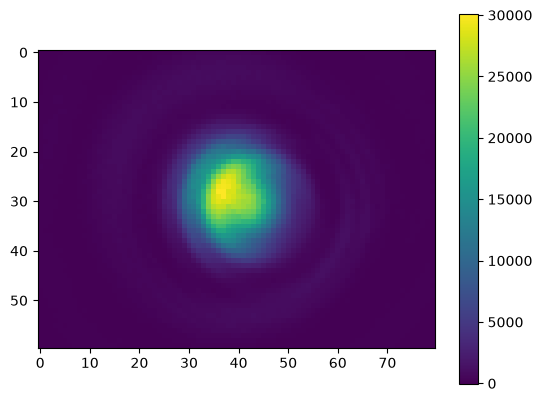

In [137]:
# try 1st w/ [a: position 3, 5mm] [ imgfb_obs1_star1_a ] **REDUCED IMAGE**

plt.figure()#figsize=(12,9))
plt.imshow(imgfb_obs1_star1_a[200:260,400:500], cmap='gray')
# add in to show WCS coords, etc
plt.colorbar();
#plt.title()

plt.figure()#figsize=(12,9))
#plt.imshow(np.log(imgfb_obs1_star1_a[200:260,400:500]), cmap='gray', vmax=np.max(np.log(imgfb_obs1_star1_a[200:260,400:500]))*90/100,
#          vmin=np.min(np.log(imgfb_obs1_star1_a[200:260,400:500]))*99/100)
plt.imshow(imgfb_obs1_star1_a[200:260,400:480], #cmap='gray', 
         #  vmin=0,#np.min(imgfb_obs1_star1_a[200:260,400:500])*99/100,
           vmax=np.max(imgfb_obs1_star1_a[200:260,400:480]*99.5/100)
          )
# add in to show WCS coords, etc
plt.colorbar();
#plt.title()

In [166]:
imgfb_obs1_star1_a[200:260,400:500] # there are negative values in the array

array([[ 24,  44,  50, ...,  10,   4,  30],
       [ 25,  68,  49, ...,  14,  48,  23],
       [ 56,  45,  78, ...,  18,  39,  32],
       ...,
       [ 27,  47,  56, ...,  24,  11,  10],
       [ 23,  -4,  38, ...,  -7,  -3,  37],
       [ 18,  36,  36, ..., -14,  -2,   5]], shape=(60, 100), dtype=int32)

In [169]:
tester_imgfb_obs1_star1_a = (imgfb_obs1_star1_a[200:260,400:480])*1 # only looking at section of interest
tester_imgfb_obs1_star1_a[tester_imgfb_obs1_star1_a<500] = 0
tester_imgfb_obs1_star1_a, np.mean(tester_imgfb_obs1_star1_a)

(array([[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]], shape=(60, 80), dtype=int32),
 np.float64(1763.85875))

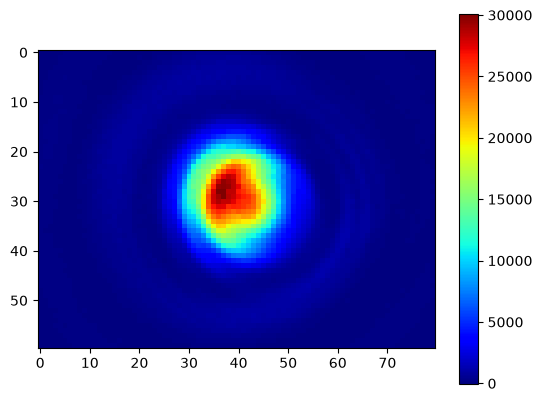

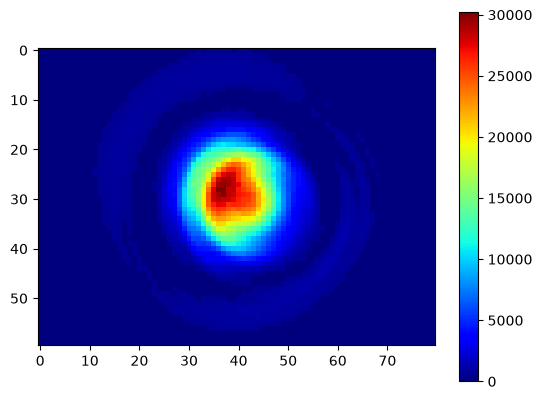

In [172]:
# trying setting all pixels *below* a certain value to zero, to try & avg out the background
plt.figure()#figsize=(12,9))
plt.imshow(imgfb_obs1_star1_a[200:260,400:480], cmap='jet', 
         #  vmin=0,#np.min(imgfb_obs1_star1_a[200:260,400:500])*99/100,
           vmax=np.max(imgfb_obs1_star1_a[200:260,400:480]*99.5/100)
          )
plt.colorbar();
#plt.title()

plt.figure()#figsize=(12,9))
plt.imshow(tester_imgfb_obs1_star1_a, cmap='jet', 
           vmin=0,#np.min(imgfb_obs1_star1_a[200:260,400:500])*99/100,
          # vmax=np.max(imgfb_obs1_star1_a[200:260,400:480]*99.5/100)
          )
plt.colorbar();
#plt.title()

# => save this image to 'analysis' subfolder in data directory, then open in SAOImage DS9 to try & get the coords now

##### Attempt 2

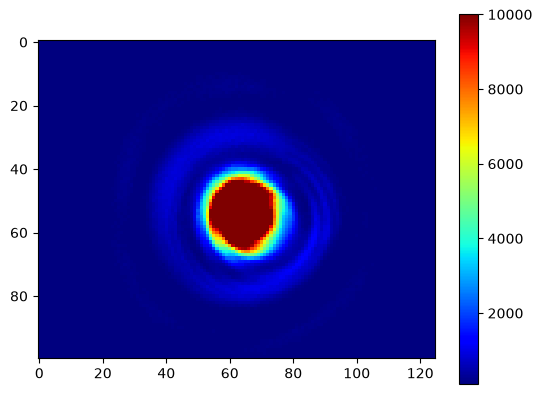

In [217]:
plt.figure()#figsize=(12,9))
plt.imshow(imgfb_obs1_star1_a[175:275,375:500], cmap='jet', vmin=100, vmax=10000)
plt.colorbar();

In [227]:
# now make copy of image, & set anything below vmin=100 to 0 (or vmin), & anything above vmax=10000 to vmax
copy_obs1_star1_a = 1*imgfb_obs1_star1_a[175:275,375:500]
copy_obs1_star1_a[copy_obs1_star1_a<=100] = 0 #100
copy_obs1_star1_a[copy_obs1_star1_a>=10_000] = 10_000

print(np.mean(imgfb_obs1_star1_a[175:275,375:500]), np.mean(copy_obs1_star1_a))
# NOTE: as changing the pixel values, can*not* use these images when getting the photon count [thresholding the image]

752.86848 521.1632


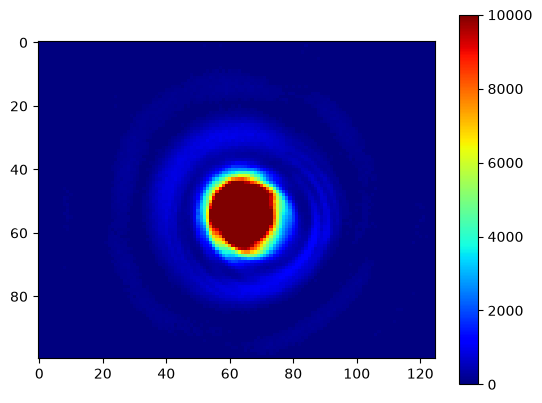

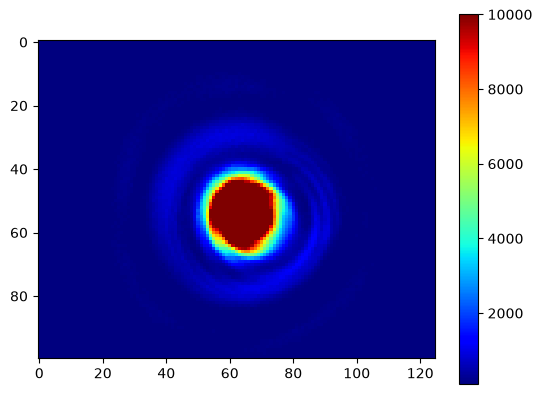

In [228]:
plt.figure()#figsize=(12,9))
plt.imshow(copy_obs1_star1_a, cmap='jet')#, vmin=100)#, vmin=100, vmax=10000)
plt.colorbar();

plt.figure()#figsize=(12,9))
plt.imshow(copy_obs1_star1_a, cmap='jet', vmin=100)#, vmin=100, vmax=10000)
plt.colorbar();

In [229]:
# calling FITS file for image "copy_obs1_star1_a" : threshold_obs1_1a [as for Task 1a, & image = thresholded]
newHeader_threshold_1a = fits.PrimaryHDU(copy_obs1_star1_a)
newHeader_threshold_1a.writeto(filepath+"analysis/obs1_1/threshold_obs1_1a.fits")   

In [ ]:
plt.figure()#figsize=(12,9))
plt.imshow(copy_obs1_star1_a, cmap='jet', origin='lower') # setting origin=lower so have [x,y=0,0] @bottom left
plt.colorbar();
#from looking at image in SAOImageDS9, can fit a circle with central coords: (65, 55) [uncertainty ~ 0.5], radius~17
plt.axvline(65, color='m', linestyle='--'); # vertical line
plt.axhline(55, color='m'); # horizontal line

# eqn of a circle: x=x0 + rcosθ, y = y0 + rsinθ
plt.plot(65 + 17*np.cos(np.linspace(0, 2*np.pi, 50)), 55 + 17*np.sin(np.linspace(0, 2*np.pi, 50)), 'm.',
           linewidth=0.05);
# => so expect distance from [centre of] maxima to 1st ring to be ~ **minimum** 17 pixels

# want to plot a larger circle that ~ traces end of 1st dark ring
plt.plot(65 + 21*np.cos(np.linspace(0, 2*np.pi, 50)), 55 + 21*np.sin(np.linspace(0, 2*np.pi, 50)), color='orange', 
            linestyle=':');

In [10]:
# central coords [x0,y0] for a = [65, 55]
# some coordinates at start of 1st dark ring: [x1,x2] = [65, 38], 

# distance from [centre of] maxima to 1st dark ring => = sqrt( (x2-x1)^2 + (y2-y1)^2 )
print(np.sqrt((65-65)**2 + (38-55)**2))
func_radius(x1=[65, 81, 49.47, 74.6859], y1=[38, 63, 54.5, 40.9835], x0=65, y0=55)

17.0


array([17.        , 17.88854382, 15.53804685, 17.0375741 ])

#### X

## Task 2.2

[Presumably are again doing for the 3 images used above / app1,2,3]   
- <b>Estimate</b> the <u>total number of counts</u> in the <u>Airy disk</u> "pixel by pixel"
    - $\neq$ forget to *estimate* the background & subtract it
    - __& Determine__ the equivalent stellar magnitude
        - assuming that the <u>quantum efficiency</u> = 50%
        - <u>Note:</u> A "zero magnitude star" provides 170 photons/msec <u>over</u> an aperture w/5mm diameter in the V-band (550$\pm$100nm) 

### Counts in Airy Disk

In [11]:
# really will get better results once have reduced the images...

# 1) total number of counts in Airy disk *pixel by pixel*

# 2) estimate bkgrd & subtract from total counts

#### Trying 1st w/ [a: position 3, 5mm]

### Determining equivalent Stellar Magnitude

In [12]:
# want counts [~ number of photons] from part a
    # told quantum efficiency = 50% => assume *real* photon amount = twice photon count
    # 1) A "zero magnitude star" => 170 photons/msec over 5mm diameter aperture in the V-band (550±100nm)
    # 2) Observing band we used is different, only used 5mm aperture for 1 image [so may not be able to do for 1mm & 3mm diameters?], 
        # & need to normalise over the exposure time [used 30 secs for each image]

print(f'Expect to get ~ {170*1e3*30} photons per 30 sec over 5mm aperture in the V-band') # 170 photons/millisec to per 30 sec

# normally, for apparent magnitudes: m1 - m_ref = -2.5*log10(F1/F_ref) 
    # could take F as the photon counts here, *BUT* difference in spectral bands -> 
        # only took these images in *R filter* => convert m_v to m_r, then work as if data~r-band
            # transmission function? => check manual/supervisor
# => supervisor says we can just ignore the difference in filters/bands [act as if they're the same band]
    # & do for the different apertures


Expect to get ~ 5100000.0 photons per 30 sec over 5mm aperture in the V-band


## Task 2.3

- Aperture mask set to position 4 / 2 appertures, each of 1mm-diameter, with baseline separation = 5mm
    - Airy disk in images should now look like Fig12b [*fringes*] / Fig5 of manual
    - Images taken with spectral filters: B, C, G, R
- __Compute__ the <u>theoretical value</u> for the <u>fringe spacing</u> ("as discussed in Sect. 6.2")
    - fringe spacing $ = \frac{\lambda}{B}$
        - "Notation for the fringe spacing in milli arcsec (mas): $α/mas = 206 \frac{λ/μm}{B/m}$, with λ in μm"
- __Measure__ the <u>fringe spacing</u> __by__ noting the pixel coords of the cursor [SAO Image DS9]

### Measurement from Data

In [13]:
# record the fringe spacing via the pixel coords, then convert to [milli] arcsecs as before
    # could take a few measurements [of r], & then take the mean?
    # have r = sqrt( (x2-x1)^2 + (y2-y1)^2 )
        # & err_r = 
    # "1.77 arcsec/pixel" => 

# spectral filters B, C, G, R



### Computation from Theory

In [14]:
# fringe spacing = lambda / Baseline B => alpha [milli arcsec] = 206* lambda[mu m] / B [m]
    # lambda = in [mu m]
    # Baseline B = 5mm = 0.5cm = 0.005m
206*lamp_lambda/0.005 # milli arc sec

# can also get uncertainty using error propagation, as have uncertainty in lambda [better comparison w/image data]


25956.0

## Task 2.4

- Aperture mask set to position 4 / 2 appertures, each of 1mm-diameter, with baseline separation = 5mm
    - Airy disk in images should now look like Fig12b [*fringes*] / Fig5 of manual
    - Images taken with spectral filters: B, C, G, R
- __How many fringes__ do you *see* in <u>total</u>?
    - __Compare__ to the *theoretical value*  given by the <u>spectral bandwidth</u> ("see Sect. 4")
        - expect ~ $\frac{2\lambda}{\Delta \lambda}$ fringes, where (if I'm reading manual right) if told spectral band = $x \pm \Delta x$ nm, then $\lambda = x$ & $\Delta \lambda = 2 \times \Delta x$

### Measurement from Data

In [15]:
# spectral filters B, C, G, R

# how many *fringes* do you see in total? 



### Computation from Theory

In [16]:
# total fringes = ~ 2*lambda/delta_lambda, where delta_lambda = 2*uncertainty_lambda
            #   = lambda/err_lamda
lamp_lambda/err_lamp_lambda

12.6

# Also Sections 10.1 "Geometrical Constellation" [Tasks 1.1 & 1.2] AND 10.3 "Visibility Measurements" [Task 3.(1-5)] AND 10.4 "Data Analysis" [4.1 & 4.2]